In [1]:
import polars as pl
import pandas as pd

import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path


In [2]:
pl.Config.set_tbl_rows(30)

polars.config.Config

In [3]:
!ls ../data -al

drwxr-xr-x    - mihalko 26 сен 11:49  .
drwxr-xr-x    - mihalko 27 сен 18:49  ..
.rw-r--r-- 196M mihalko 11 сен 11:17  benchmark_items.parquet
.rw-r--r-- 127k mihalko 11 сен 11:17  benchmark_queries.parquet
.rw-r--r-- 490M mihalko 11 сен 11:19  train.parquet


In [4]:
DATA_PATH = Path("../data")
TRAIN_PARQUET = "train.parquet" 
BENCH_ITEMS = "benchmark_items.parquet"
BENCH_QUERIES = "benchmark_queries.parquet"

# Схема, просмотр головы

In [5]:
train_df = pl.scan_parquet(DATA_PATH / TRAIN_PARQUET)

print("Schema")
print(50 * "-")
for col, col_t in train_df.collect_schema().items():
    print(f"Колонка {col} с типом {col_t}")

# print(f"Dataset length: {len(train_df)}")
print(50 * "-")

print("Data head")
print(50 * "-")
train_df.head(10).collect()

Schema
--------------------------------------------------
Колонка search_query с типом String
Колонка search_location_id с типом Int64
Колонка search_is_delivery_search с типом Int32
Колонка search_infm_params_text с типом String
Колонка search_category с типом Int64
Колонка item_title_raw с типом String
Колонка item_rating_reviews_count с типом Float64
Колонка item_rating с типом Float64
Колонка item_price с типом Decimal(precision=27, scale=15)
Колонка item_microcat_id с типом Int64
Колонка item_longitude с типом Decimal(precision=18, scale=15)
Колонка item_location_id с типом Int64
Колонка item_latitude с типом Decimal(precision=17, scale=15)
Колонка item_is_phone_hidden с типом Boolean
Колонка item_is_message_forbidden с типом Boolean
Колонка item_infm_params_text с типом String
Колонка item_id с типом String
Колонка item_description_raw с типом String
Колонка item_category_id с типом Int64
--------------------------------------------------
Data head
-------------------------------

search_query,search_location_id,search_is_delivery_search,search_infm_params_text,search_category,item_title_raw,item_rating_reviews_count,item_rating,item_price,item_microcat_id,item_longitude,item_location_id,item_latitude,item_is_phone_hidden,item_is_message_forbidden,item_infm_params_text,item_id,item_description_raw,item_category_id
str,i64,i32,str,i64,str,f64,f64,"decimal[27,15]",i64,"decimal[18,15]",i64,"decimal[17,15]",bool,bool,str,str,str,i64
"""скупка телевизоров""",652430,0,"""""",114,"""Скупка б/у техники""",91.0,4.989011,1.000000000000000,2303374,39.712818145751953,652430,54.629230499267578,true,false,"""Вид услуги Место оказания услу…","""e8b685dffe1a408e""","""Скупаю практически любую совре…",114
"""автоподбор""",640860,0,"""Рейтинг пользователя 4 звезды …",114,"""Автоподбор Разовый осмотр авто…",462.0,4.982684,3500.000000000000000,2303374,44.051009999999998,640860,56.273389999999999,false,false,"""Вид услуги Место оказания услу…","""92e1b0446f827b59""","""🚗 Автоподбор и выездная диагно…",114
"""баня на дровах""",653240,0,"""Онлайн-запись Тип услуги СПА-у…",114,"""Баня на дровах ""Прованс"" на Цв…",null,null,1600.000000000000000,86469,30.128784180000000,653240,59.783687590000000,false,false,"""Вид услуги Красота, здоровье М…","""624846856ce81d69""","""В ритме современной жизни так…",114
"""изготовление госномера на авто""",634670,0,"""Вид услуги Оборудование, произ…",114,"""Изготовление дубликатов авто н…",14.0,4.714286,1700.000000000000000,2303428,40.537841000000000,633570,45.424875000000000,false,false,"""Вид услуги Оборудование, произ…","""45b8628b9c6e7b85""","""Изготовим дубликат номера по у…",114
"""укладка плитки""",658430,0,"""Тип услуги Ремонт квартир и до…",114,"""Ремонт и отделка квартир под к…",1.0,5.0,1000.000000000000000,44725,69.496444699999998,658430,56.105983729999998,false,false,"""Вид услуги Ремонт и отделка Ти…","""c95a4a7daf2a967f""","""отделочные работы любой сложно…",114
"""сборка мебели""",639550,0,"""Тип услуги Сборка и ремонт меб…",114,"""Сборка мебели""",27.0,5.0,1500.000000000000000,44732,38.009048999999997,637770,55.746436000000003,false,false,"""Вид услуги Ремонт и отделка Ти…","""1ff95304df4f6b86""","""сборка мебели""",114
"""наращивание ногтей""",107620,0,"""Онлайн-запись Тип услуги Маник…",114,"""Мастер маникюр и педикюра""",47.0,4.914894,700.000000000000000,86470,37.868247990000000,637640,55.742385859999999,false,false,"""Вид услуги Красота, здоровье М…","""78c2899bda9f2375""","""Милые Дaмы💞 Пpиглaшаю вас на м…",114
"""установка входных дверей""",638520,0,"""""",114,"""Установка межкомнатных дверей""",129.0,4.852713,4000.000000000000000,1287635,37.815212250000002,638520,55.918952939999997,false,false,"""Вид услуги Ремонт и отделка Ти…","""0c87b772d5644e6d""","""Установка межкомнатных дверей …",114
"""выкуп компьютеров""",661420,0,"""Вид услуги""",114,"""Выкуп пк, ноутбуков,приставок""",1071.0,4.984127,100000.000000000000000,2303374,61.308090000000000,661420,55.174182999999999,false,false,"""Вид услуги Место оказания услу…","""1806b31ef88a665f""","""Срoчный Выкуп Bидeокарт,Ноутбу…",114


In [6]:
# the number of non-null elements for each column
train_df.count().collect()

search_query,search_location_id,search_is_delivery_search,search_infm_params_text,search_category,item_title_raw,item_rating_reviews_count,item_rating,item_price,item_microcat_id,item_longitude,item_location_id,item_latitude,item_is_phone_hidden,item_is_message_forbidden,item_infm_params_text,item_id,item_description_raw,item_category_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
497673,497673,497673,497673,497673,497673,478462,469441,497673,497673,497669,497673,497669,497673,497673,497673,497673,497673,497673


# Распределения для целочисленных признаков

In [33]:
int_cols = train_df.select(
    ["search_location_id", "search_is_delivery_search", "search_category",
     "item_location_id", "item_microcat_id", "item_category_id",
     pl.col("item_rating_reviews_count").cast(pl.Int64)]
).collect()

print(50 * "-")
print("Summary on location id")
print(50 * "-")

print(f"Unique search locations: {len(int_cols["search_location_id"].unique())}") 
print(f"Unique item locations: {len(int_cols["item_location_id"].unique())}")
print(f"Count of null search_locations: {len(int_cols.filter(pl.col("search_location_id").is_null()))}")
print(f"Count of null item_locations: {len(int_cols.filter(pl.col("item_location_id").is_null()))}")
print(f"Count of examples with unequal locations: {len(int_cols.filter(pl.col("search_location_id") != pl.col("item_location_id")))}")

print(50 * "-")
print("Summary on delivery search")
print(50 * "-")

print(f"Unique delivery searches: {len(int_cols["search_is_delivery_search"].unique())}") 
print(f"Count of null delivery search: {len(int_cols.filter(pl.col("search_is_delivery_search").is_null()))}")

print(50 * "-")
print("Summary on reviews")
print(50 * "-")

print(f"Unique reviews: {len(int_cols["item_rating_reviews_count"].unique())}") 
print(f"Count of null reviews: {len(int_cols.filter(pl.col("item_rating_reviews_count").is_null()))}")

print(50 * "-")
print("Summary on categories")
print(50 * "-")

print(f"Unique search categories: {len(int_cols["search_category"].unique())}") 
print(f"Unique item categories: {len(int_cols["item_category_id"].unique())}")
print(f"Unique item subcategories: {len(int_cols["item_microcat_id"].unique())}")
print(f"Count of null search categories: {len(int_cols.filter(pl.col("search_category").is_null()))}")
print(f"Count of null item categories: {len(int_cols.filter(pl.col("item_category_id").is_null()))}")
print(f"Count of null item subcategories: {len(int_cols.filter(pl.col("item_microcat_id").is_null()))}")
print(f"Count of examples with unequal categories: {len(int_cols.filter(pl.col("search_category") != pl.col("item_category_id")))}")


--------------------------------------------------
Summary on location id
--------------------------------------------------
Unique search locations: 2782
Unique item locations: 2637
Count of null search_locations: 0
Count of null item_locations: 0
Count of examples with unequal locations: 84097
--------------------------------------------------
Summary on delivery search
--------------------------------------------------
Unique delivery searches: 2
Count of null delivery search: 0
--------------------------------------------------
Summary on reviews
--------------------------------------------------
Unique reviews: 1373
Count of null reviews: 19211
--------------------------------------------------
Summary on categories
--------------------------------------------------
Unique search categories: 4
Unique item categories: 8
Unique item subcategories: 212
Count of null search categories: 0
Count of null item categories: 0
Count of null item subcategories: 0
Count of examples with unequa

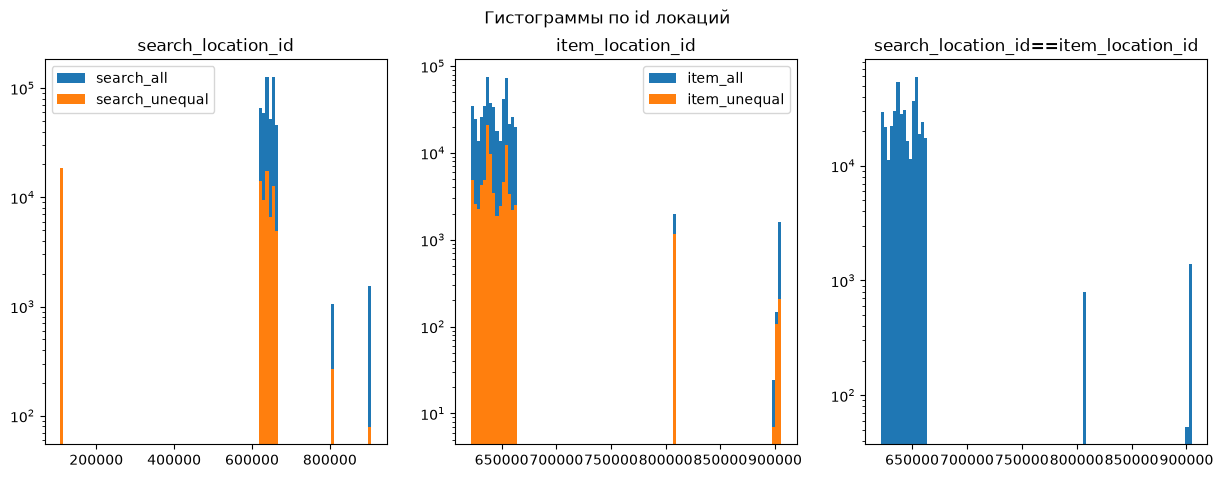

In [17]:
locations_bins = 100

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].hist(int_cols["search_location_id"], bins=locations_bins, log=True, label="search_all")
ax[1].hist(int_cols["item_location_id"], bins=locations_bins, log=True, label="item_all")
ax[2].hist(int_cols.filter(pl.col("search_location_id") == pl.col("item_location_id"))["item_location_id"], bins=locations_bins, log=True, label="all")

ax[0].set(title="search_location_id")
ax[1].set(title="item_location_id")
ax[2].set(title="search_location_id==item_location_id")

ax[0].hist(int_cols.filter(pl.col("search_location_id") != pl.col("item_location_id"))["search_location_id"], bins=locations_bins, log=True, label="search_unequal")
ax[1].hist(int_cols.filter(pl.col("search_location_id") != pl.col("item_location_id"))["item_location_id"], bins=locations_bins, log=True, label="item_unequal")


fig.suptitle(f"Гистограммы по id локаций")
ax[0].legend()
ax[1].legend()

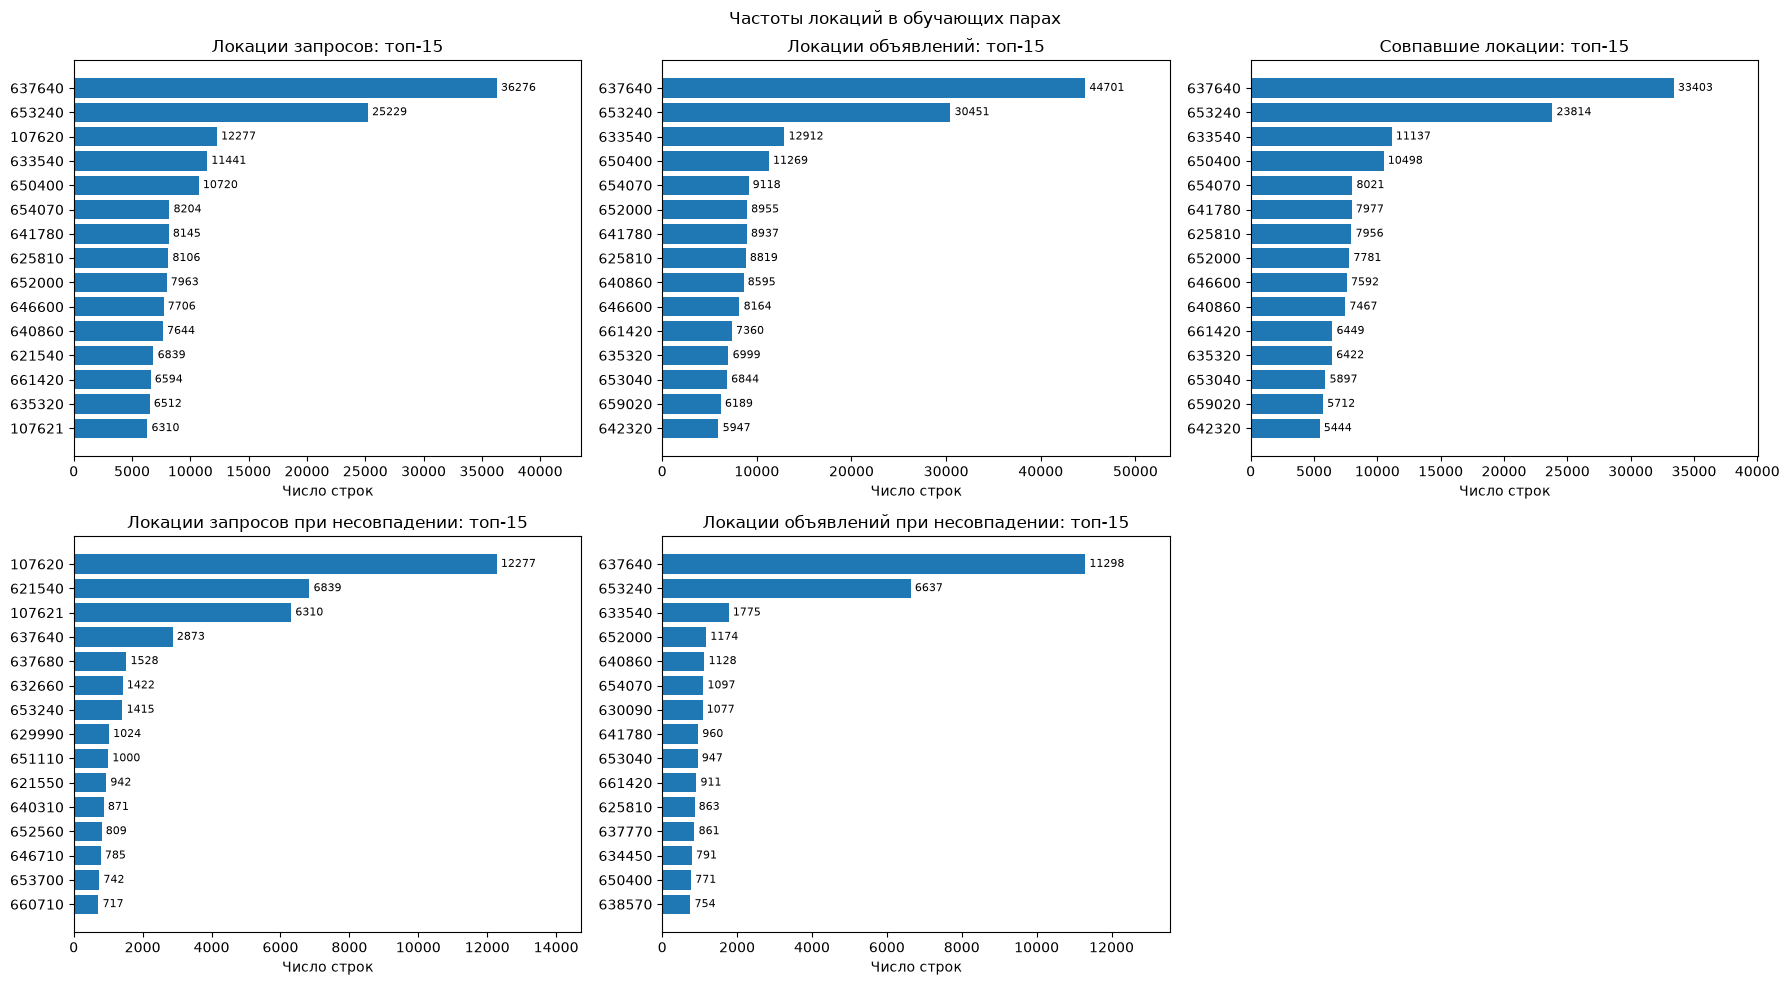

In [9]:
def category_bar(series, ax, title, top=None, log=False):
    counts = series.value_counts().sort("count", descending=True)
    if top is not None:
        counts = counts.head(top)
    counts = counts.reverse()
    bars = ax.barh(counts[series.name].cast(pl.String).to_list(), counts["count"].to_list())
    ax.bar_label(bars, padding=3, fontsize=8)
    if log:
        ax.set_xscale("log")
    ax.set(title=title, xlabel="Число строк")
    ax.margins(x=0.2)


same_location = int_cols.filter(pl.col("search_location_id") == pl.col("item_location_id"))
different_location = int_cols.filter(pl.col("search_location_id") != pl.col("item_location_id"))

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
category_bar(int_cols["search_location_id"], ax[0, 0], "Локации запросов: топ-15", top=15)
category_bar(int_cols["item_location_id"], ax[0, 1], "Локации объявлений: топ-15", top=15)
category_bar(same_location["item_location_id"], ax[0, 2], "Совпавшие локации: топ-15", top=15)
category_bar(different_location["search_location_id"], ax[1, 0], "Локации запросов при несовпадении: топ-15", top=15)
category_bar(different_location["item_location_id"], ax[1, 1], "Локации объявлений при несовпадении: топ-15", top=15)
fig.delaxes(ax[1, 2])
fig.suptitle("Частоты локаций в обучающих парах")
fig.tight_layout()
plt.show()


Text(0.5, 1.0, 'Гистограмма по item_rating_reviews_count')

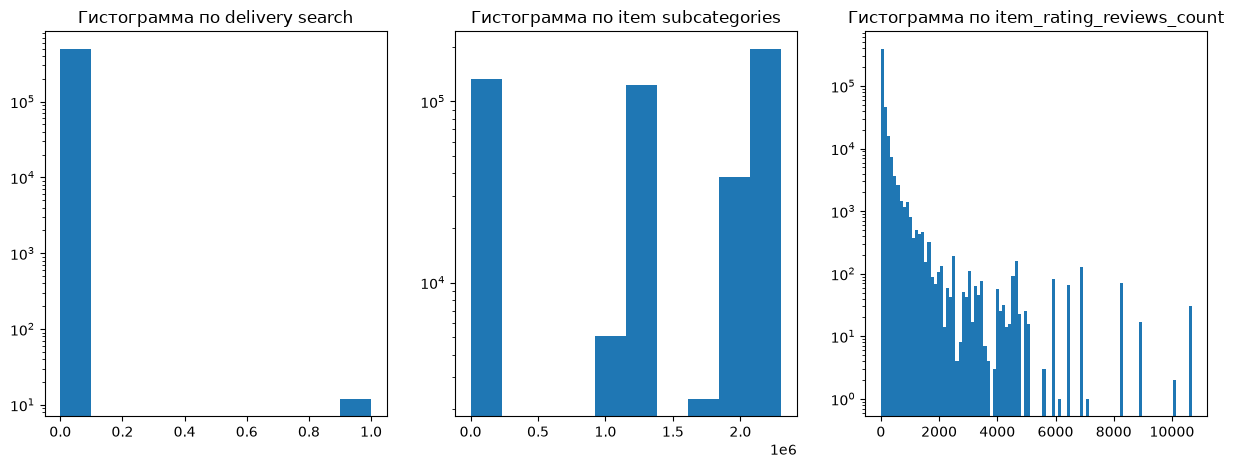

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].hist(int_cols["search_is_delivery_search"], log=True)
ax[1].hist(int_cols["item_microcat_id"], log=True)
ax[2].hist(int_cols["item_rating_reviews_count"], log=True, bins=100)

ax[0].set_title(f"Гистограмма по delivery search")
ax[1].set_title(f"Гистограмма по item subcategories")
ax[2].set_title(f"Гистограмма по item_rating_reviews_count")

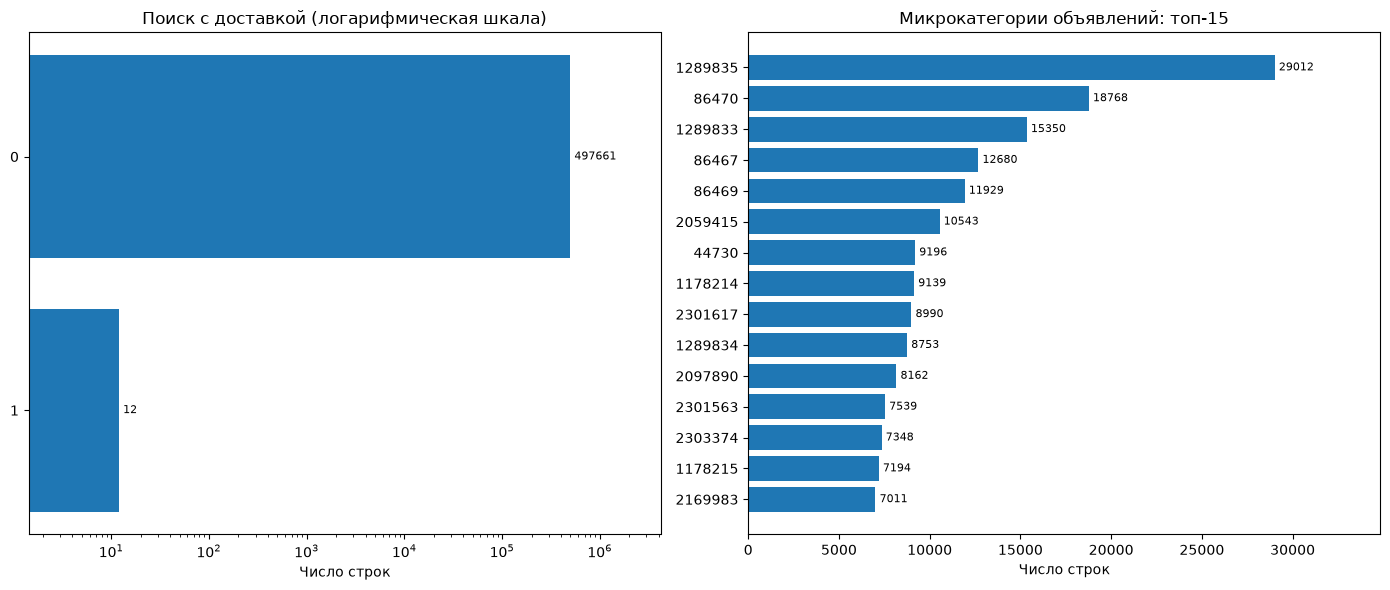

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
category_bar(int_cols["search_is_delivery_search"], ax[0], "Поиск с доставкой (логарифмическая шкала)", log=True)
category_bar(int_cols["item_microcat_id"], ax[1], "Микрокатегории объявлений: топ-15", top=15)
fig.tight_layout()
plt.show()


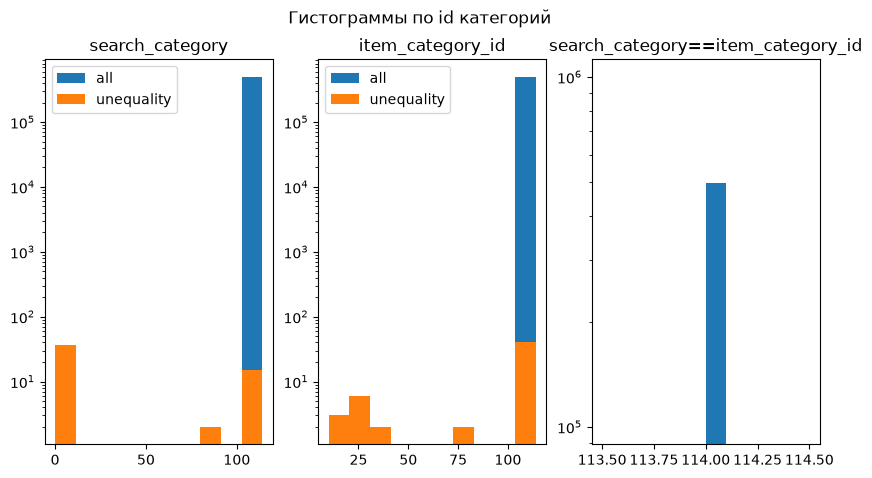

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
ax[0].hist(int_cols["search_category"], log=True, label="all")
ax[1].hist(int_cols["item_category_id"], log=True, label="all")
ax[2].hist(int_cols.filter(pl.col("search_category") == pl.col("item_category_id"))["item_category_id"], log=True, label="equality")

ax[0].set(title="search_category")
ax[1].set(title="item_category_id")
ax[2].set(title="search_category==item_category_id")

ax[0].hist(int_cols.filter(pl.col("search_category") != pl.col("item_category_id"))["search_category"], log=True, label="unequality")
ax[1].hist(int_cols.filter(pl.col("search_category") != pl.col("item_category_id"))["item_category_id"], log=True, label="unequality")

fig.suptitle(f"Гистограммы по id категорий")
ax[0].legend()
ax[1].legend()


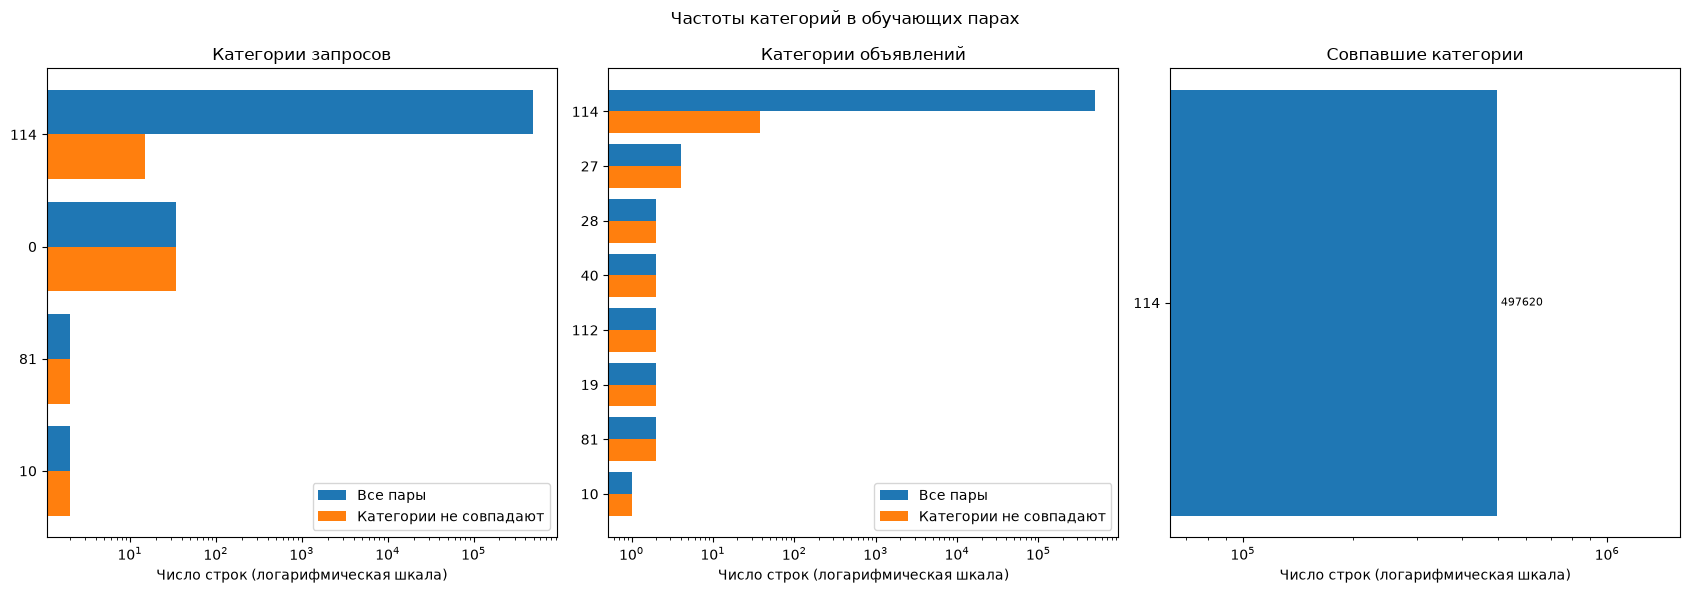

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for axis, col, title in zip(
    ax[:2],
    ["search_category", "item_category_id"],
    ["Категории запросов", "Категории объявлений"],
):
    counts = int_cols.group_by(col).agg(
        pl.len().alias("all"),
        (pl.col("search_category") != pl.col("item_category_id")).sum().alias("different"),
    ).sort("all", descending=True)
    positions = np.arange(counts.height)
    axis.barh(positions - 0.2, counts["all"].to_list(), height=0.4, label="Все пары")
    axis.barh(positions + 0.2, counts["different"].to_list(), height=0.4, label="Категории не совпадают")
    axis.set_yticks(positions, counts[col].cast(pl.String).to_list())
    axis.invert_yaxis()
    axis.set_xscale("log")
    axis.set(title=title, xlabel="Число строк (логарифмическая шкала)")
    axis.legend()

same_category = int_cols.filter(pl.col("search_category") == pl.col("item_category_id"))
category_bar(same_category["item_category_id"], ax[2], "Совпавшие категории", log=True)
ax[2].set_xlabel("Число строк (логарифмическая шкала)")
fig.suptitle("Частоты категорий в обучающих парах")
fig.tight_layout()
plt.show()


# Распределения булевых категориальных признаков


item_is_phone_hidden: уникальных значений 2, пропусков 0
shape: (2, 3)
┌──────────────────────┬────────┬──────────┐
│ item_is_phone_hidden ┆ count  ┆ percent  │
│ ---                  ┆ ---    ┆ ---      │
│ bool                 ┆ u32    ┆ f64      │
╞══════════════════════╪════════╪══════════╡
│ false                ┆ 437244 ┆ 87.85769 │
│ true                 ┆ 60429  ┆ 12.14231 │
└──────────────────────┴────────┴──────────┘
item_is_message_forbidden: уникальных значений 2, пропусков 0
shape: (2, 3)
┌───────────────────────────┬────────┬───────────┐
│ item_is_message_forbidden ┆ count  ┆ percent   │
│ ---                       ┆ ---    ┆ ---       │
│ bool                      ┆ u32    ┆ f64       │
╞═══════════════════════════╪════════╪═══════════╡
│ false                     ┆ 487269 ┆ 97.909471 │
│ true                      ┆ 10404  ┆ 2.090529  │
└───────────────────────────┴────────┴───────────┘
Совместные значения флагов
shape: (3, 3)
┌──────────────────────┬────────────────────

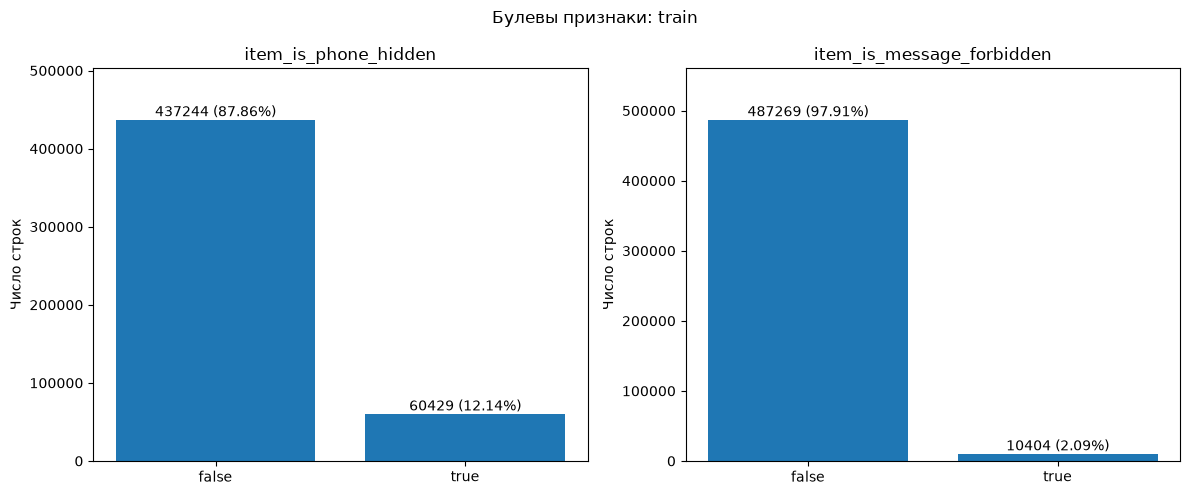

In [ ]:
bool_cols = train_df.select("item_is_phone_hidden", "item_is_message_forbidden").collect()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axis, col in zip(ax, bool_cols.columns):
    print(f"{col}: уникальных значений {bool_cols[col].drop_nulls().n_unique()}, пропусков {bool_cols[col].null_count()}")
    counts = bool_cols[col].value_counts().sort(col).with_columns(
        (100 * pl.col("count") / bool_cols.height).alias("percent")
    )
    print(counts)
    bars = axis.bar(counts[col].cast(pl.String).fill_null("null").to_list(), counts["count"].to_list())
    axis.bar_label(bars, labels=[f"{n} ({p:.2f}%)" for n, p in zip(counts["count"], counts["percent"])])
    axis.set(title=col, ylabel="Число строк")
    axis.margins(y=0.15)

print("Совместные значения флагов")
print(bool_cols.group_by(bool_cols.columns).len().sort("len", descending=True))
fig.suptitle("Булевы признаки: train")
fig.tight_layout()
plt.show()


# Распределения непрерывных числовых типов

In [36]:
float_cols = train_df.select(["item_rating", "item_longitude", "item_latitude", "item_price"])
float_cols.head(10).collect()

item_rating,item_longitude,item_latitude,item_price
f64,"decimal[18,15]","decimal[17,15]","decimal[27,15]"
4.989011,39.712818145751953,54.629230499267578,1.000000000000000
4.982684,44.051009999999998,56.273389999999999,3500.000000000000000
null,30.128784180000000,59.783687590000000,1600.000000000000000
4.714286,40.537841000000000,45.424875000000000,1700.000000000000000
5.0,69.496444699999998,56.105983729999998,1000.000000000000000
5.0,38.009048999999997,55.746436000000003,1500.000000000000000
4.914894,37.868247990000000,55.742385859999999,700.000000000000000
4.852713,37.815212250000002,55.918952939999997,4000.000000000000000
4.984127,61.308090000000000,55.174182999999999,100000.000000000000000


In [37]:
float_cols.describe()

statistic,item_rating,item_longitude,item_latitude,item_price
str,f64,f64,f64,f64
"""count""",469441.0,497669.0,497669.0,497673.0
"""null_count""",28232.0,4.0,4.0,0.0
"""mean""",4.81675,49.399462,53.875558,1.9711e7
"""std""",0.658251,20.629442,4.793171,3.8276e9
"""min""",0.0,-118.423729,-32.93322,-1.0
"""25%""",4.882353,37.610444,51.800275,400.0
"""50%""",5.0,40.926857,55.173115,1000.0
"""75%""",5.0,55.131298,56.262877,2000.0
"""max""",5.0,177.518913,71.639263,1.0000e12


Графики считаются по строкам обучающих пар: повторяющиеся объявления учитываются повторно. Пропуски исключены из соответствующих графиков. Для цены используется `log1p` неотрицательных значений, число отрицательных значений выводится отдельно.

Совместное распределение координат показано через `hexbin`. У двух панелей собственные сетки и цветовые шкалы; правая увеличивает область между 1-м и 99-м процентилями каждой координаты.


Цена: отрицательных значений 32631, нулей 4995


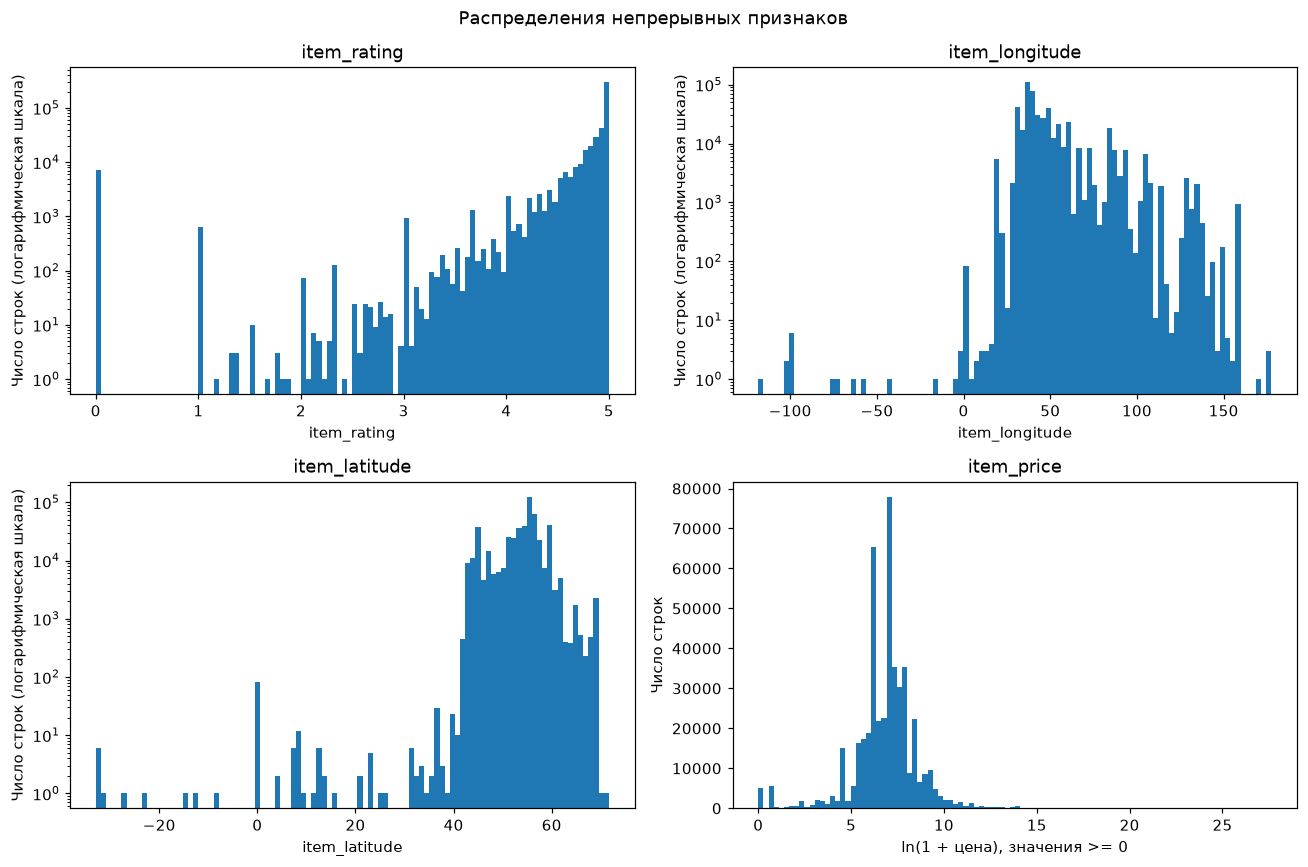

In [ ]:
numeric_data = float_cols.select(pl.all().cast(pl.Float64)).collect()

fig, ax = plt.subplots((numeric_data.width + 1) // 2, 2, figsize=(12, 8), squeeze=False)
for axis, col in zip(ax.flat, numeric_data.columns):
    values = numeric_data[col].drop_nulls().to_numpy()
    values = values[np.isfinite(values)]
    if col == "item_price":
        print(f"Цена: отрицательных значений {(values < 0).sum()}, нулей {(values == 0).sum()}")
        axis.hist(np.log1p(values[values >= 0]), bins=100)
        axis.set(title=col, xlabel="ln(1 + цена), значения >= 0", ylabel="Число строк")
    else:
        axis.hist(values, bins=100, log=True)
        axis.set(title=col, xlabel=col, ylabel="Число строк (логарифмическая шкала)")

for axis in list(ax.flat)[numeric_data.width:]:
    fig.delaxes(axis)
fig.suptitle("Распределения непрерывных признаков")
fig.tight_layout()
plt.show()


### KDE непрерывных признаков

KDE оценивается по случайной выборке до 20 000 строк для каждого признака (seed=42), ширина сглаживания — по правилу Скотта. Для сравнения гистограмма всех значений нормирована до плотности; ось Y линейная. Цена показана после `log1p` неотрицательных значений. Гауссово сглаживание выходит за границы данных: хвосты вне рейтинга [0, 5] и отрицательные значения преобразованной цены — эффект оценки, а не наблюдения.


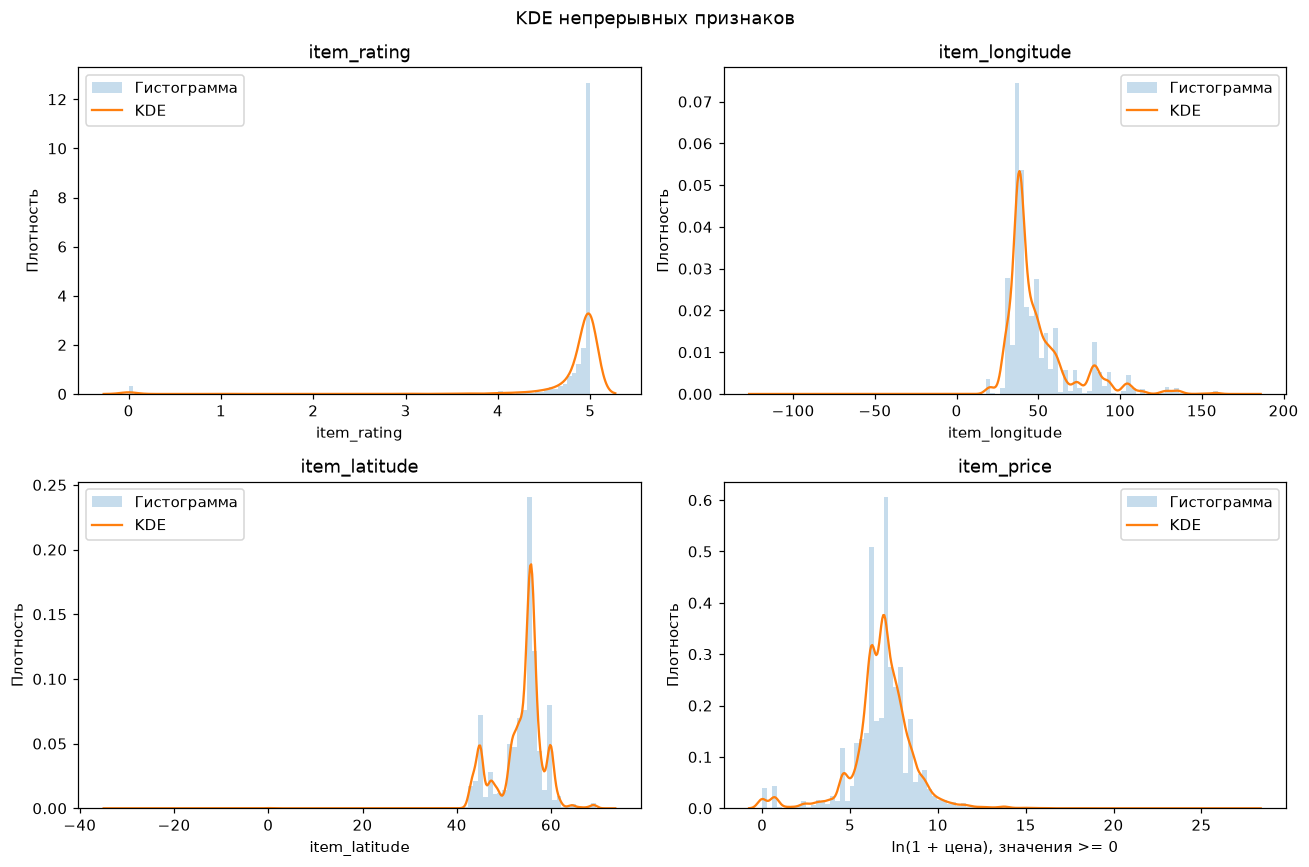

In [ ]:
from matplotlib.mlab import GaussianKDE

numeric_data = float_cols.select(pl.all().cast(pl.Float64)).collect()
rng = np.random.default_rng(42)

fig, ax = plt.subplots((numeric_data.width + 1) // 2, 2, figsize=(12, 8), squeeze=False)
for axis, col in zip(ax.flat, numeric_data.columns):
    values = numeric_data[col].drop_nulls().to_numpy()
    values = values[np.isfinite(values)]
    xlabel = col
    if col == "item_price":
        values = np.log1p(values[values >= 0])
        xlabel = "ln(1 + цена), значения >= 0"

    sample = rng.choice(values, size=min(20_000, len(values)), replace=False)
    kde = GaussianKDE(sample, bw_method="scott")
    bandwidth = np.sqrt(kde.covariance[0, 0])
    grid = np.linspace(values.min() - 3 * bandwidth, values.max() + 3 * bandwidth, 512)

    axis.hist(values, bins=100, density=True, alpha=0.25, label="Гистограмма")
    axis.plot(grid, kde(grid), label="KDE")
    axis.set(title=col, xlabel=xlabel, ylabel="Плотность")
    axis.legend()

for axis in list(ax.flat)[numeric_data.width:]:
    fig.delaxes(axis)
fig.suptitle("KDE непрерывных признаков")
fig.tight_layout()
plt.show()


Пар с координатами: 497669, в центральной области: 477896 (96.0%)


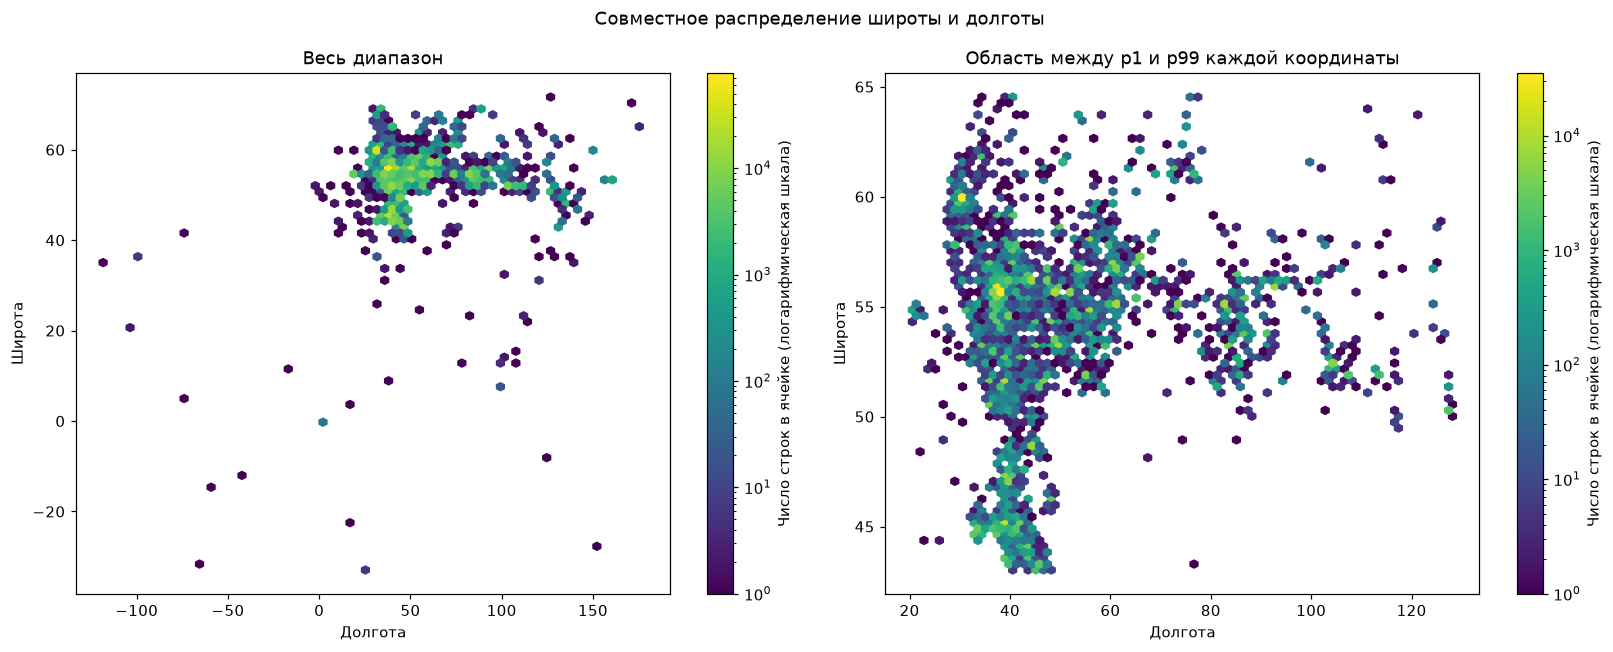

In [ ]:
coordinates = numeric_data.select("item_longitude", "item_latitude").drop_nulls().to_numpy()
coordinates = coordinates[np.isfinite(coordinates).all(axis=1)]
longitude, latitude = coordinates.T

lon_min, lon_max = np.quantile(longitude, [0.01, 0.99])
lat_min, lat_max = np.quantile(latitude, [0.01, 0.99])
central = (
    (longitude >= lon_min) & (longitude <= lon_max)
    & (latitude >= lat_min) & (latitude <= lat_max)
)
print(f"Пар с координатами: {len(coordinates)}, в центральной области: {central.sum()} ({central.mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for axis, mask, title in zip(
    ax,
    [np.ones(len(coordinates), dtype=bool), central],
    ["Весь диапазон", "Область между p1 и p99 каждой координаты"],
):
    density = axis.hexbin(
        longitude[mask], latitude[mask],
        gridsize=70, mincnt=1, bins="log", cmap="viridis",
    )
    axis.set(title=title, xlabel="Долгота", ylabel="Широта")
    fig.colorbar(density, ax=axis, label="Число строк в ячейке (логарифмическая шкала)")

fig.suptitle("Совместное распределение широты и долготы")
fig.tight_layout()
plt.show()


# Колонки с плоскими строками

In [41]:
plain_text_cols = train_df.select(["search_query", "item_title_raw", "item_description_raw", "item_id"]).collect()

print(f"Null count for all")

plain_text_cols.null_count()

Null count for all


search_query,item_title_raw,item_description_raw,item_id
u32,u32,u32,u32
0,0,0,0


Text(0.5, 0.98, 'Гистограммы длин для плоского текста')

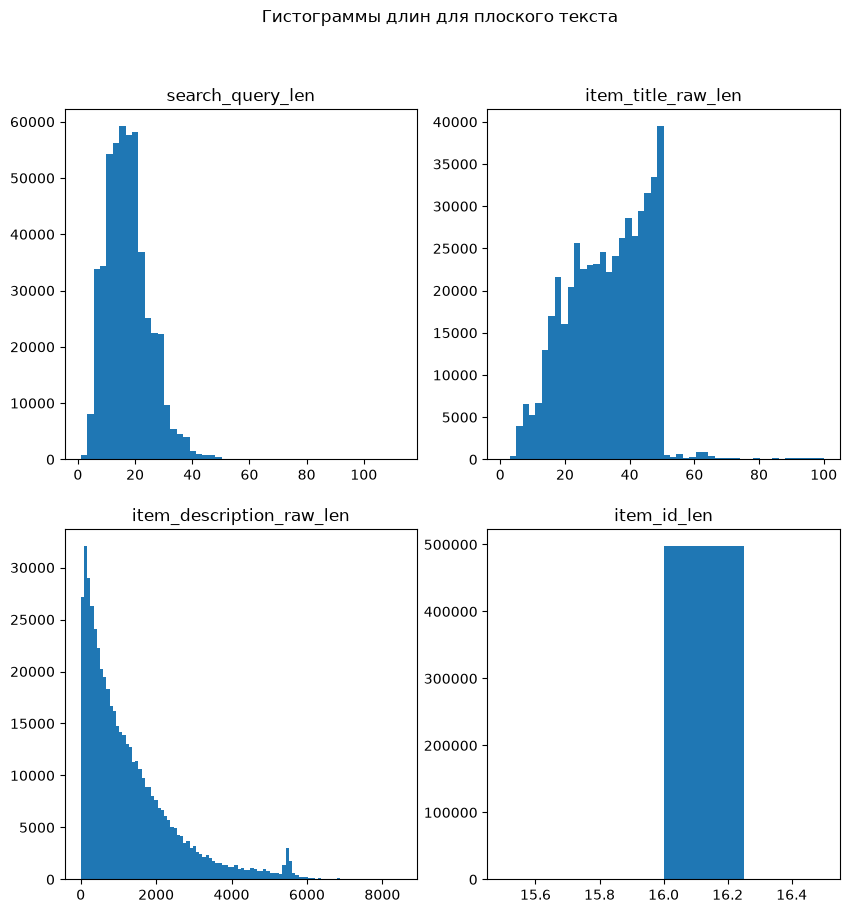

In [59]:
text_bins = {"search_query_len": 50, "item_title_raw_len": 50, "item_description_raw_len": 100, "item_id_len": 4}

lens_df = plain_text_cols.select(
    pl.col(name).str.len_chars().alias(f"{name}_len")
    for name in plain_text_cols.columns
)

fig, ax = plt.subplots(len(lens_df.columns) // 2 + len(lens_df.columns) % 2, 2, figsize=(10, 10))

for i, name in enumerate(lens_df.columns):
    ax[i // 2][i % 2].hist(lens_df[name], bins=text_bins[name])
    ax[i // 2][i % 2].set(title=name)


fig.suptitle(f"Гистограммы длин для плоского текста")

# Структурированный текст

In [61]:
sruct_text_cols = train_df.select(["search_infm_params_text", "item_infm_params_text"]).collect()

print(f"Null count for all")

sruct_text_cols.null_count()

Null count for all


search_infm_params_text,item_infm_params_text
u32,u32
0,0


Text(0.5, 0.98, 'Гистограммы длин для плоского текста')

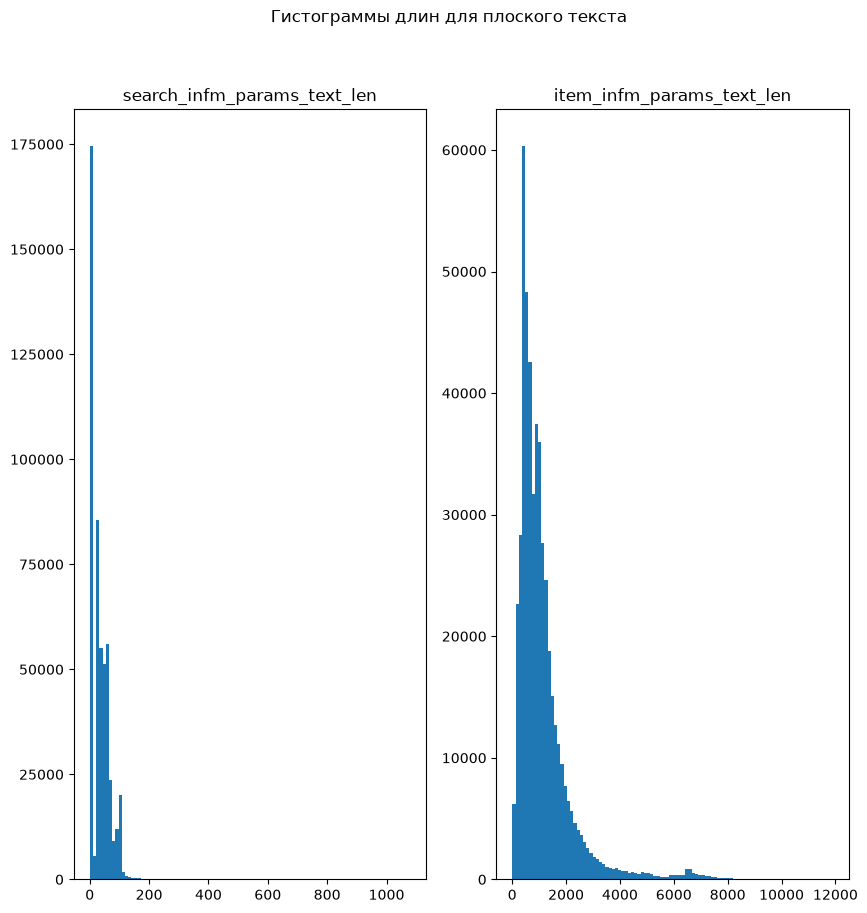

In [65]:
text_bins = {"search_infm_params_text_len": 100, "item_infm_params_text_len": 100}

lens_df = sruct_text_cols.select(
    pl.col(name).str.len_chars().alias(f"{name}_len")
    for name in sruct_text_cols.columns
)

fig, ax = plt.subplots(len(lens_df.columns) // 2 + len(lens_df.columns) % 2, 2, figsize=(10, 10))

for i, name in enumerate(lens_df.columns):
    ax[i % 2].hist(lens_df[name], bins=text_bins[name])
    ax[i % 2].set(title=name)


fig.suptitle(f"Гистограммы длин для плоского текста")

In [66]:
sruct_text_cols

search_infm_params_text,item_infm_params_text
str,str
"""""","""Вид услуги Место оказания услу…"
"""Рейтинг пользователя 4 звезды …","""Вид услуги Место оказания услу…"
"""Онлайн-запись Тип услуги СПА-у…","""Вид услуги Красота, здоровье М…"
"""Вид услуги Оборудование, произ…","""Вид услуги Оборудование, произ…"
"""Тип услуги Ремонт квартир и до…","""Вид услуги Ремонт и отделка Ти…"
"""Тип услуги Сборка и ремонт меб…","""Вид услуги Ремонт и отделка Ти…"
"""Онлайн-запись Тип услуги Маник…","""Вид услуги Красота, здоровье М…"
"""""","""Вид услуги Ремонт и отделка Ти…"
"""Вид услуги""","""Вид услуги Место оказания услу…"


In [14]:
# ненулевой delivery_search
train_df.filter(pl.col("search_is_delivery_search") != 0).collect()

search_query,search_location_id,search_is_delivery_search,search_infm_params_text,search_category,item_title_raw,item_rating_reviews_count,item_rating,item_price,item_microcat_id,item_longitude,item_location_id,item_latitude,item_is_phone_hidden,item_is_message_forbidden,item_infm_params_text,item_id,item_description_raw,item_category_id
str,i64,i32,str,i64,str,f64,f64,"decimal[27,15]",i64,"decimal[18,15]",i64,"decimal[17,15]",bool,bool,str,str,str,i64
"""грумер кошек""",628780,1,"""Вид услуги Уход за животными""",114,"""Стрижка кошек на дому""",41.0,4.902439,800.000000000000000,729,104.143684399999998,628970,52.351963040000001,false,false,"""Вид услуги Уход за животными М…","""75193b40925d30f0""","""Добрый день, я начинающий маст…",114
"""модель на чистку лица""",637640,1,"""Вид услуги Красота, здоровье""",114,"""Модель на омоложение лица, на …",0.0,null,990.000000000000000,2096640,37.616016389999999,637640,55.773941039999997,false,false,"""Вид услуги Красота, здоровье М…","""7ad69ed5dac4c6aa""","""Врач-косметолог. Визит-знакомс…",114
"""автобус на заказ 30 местомск""",621540,1,"""Вид услуги Пассажирские перево…",114,"""Заказ автобуса""",7.0,3.857143,1000.000000000000000,2097894,73.360225999999997,642320,55.002268000000001,false,false,"""Вид услуги Пассажирские перево…","""7b67a4d4daebb7c9""","""Комфортно и качественно оказыв…",114
"""массаж жулебино""",107620,1,"""""",114,"""Массаж ручной /аппаратный Жуле…",35.0,5.0,2500.000000000000000,86469,37.849147799999997,637640,55.686851500000003,false,false,"""Вид услуги Красота, здоровье М…","""86c69ea292d89b13""","""Предлагаю функциональную корре…",114
"""электроэпиляция""",621576,1,"""""",114,"""Электроэпиляция""",4.0,5.0,20.000000000000000,2096641,34.170234680000000,621576,44.510219569999997,true,false,"""Вид услуги Красота, здоровье М…","""c2f591130f429a26""","""Приглашаю девушек на электроэп…",114
"""услуги каменщика""",638150,1,"""Вид услуги Строительство""",114,"""Каменщики""",6.0,5.0,2500.000000000000000,2058736,37.759231626087342,638150,55.358424791181747,true,false,"""Вид услуги Строительство Место…","""0179806f50349321""","""облицовка кирпичом — ровно, пр…",114
"""копка земли на даче""",632490,1,"""""",114,"""Пахота земли мотокультиватором""",18.0,5.0,700.000000000000000,1178214,40.958038999999999,632490,57.924098000000001,false,false,"""Вид услуги Сад, благоустройств…","""73fc8ad9c4acdb3e""","""пахата участка звоните пишите …",114
"""обустройство скважин""",660710,1,"""Тип услуги Скважины, септики, …",114,"""Прочистка скважин""",71.0,4.84507,8000.000000000000000,1178210,61.402554000000002,661420,55.159902000000002,false,false,"""Вид услуги Сад, благоустройств…","""dfce6cececeba36a""","""Приедем оперативно к назначенн…",114
"""грузчики для вывоза строительн…",623470,1,"""""",114,"""Вывоз мусора""",31.0,4.903226,-1.000000000000000,2301617,38.100102000000000,623470,50.211326999999997,false,false,"""Вид услуги Вывоз мусора и втор…","""8696662ab4253409""","""👏 вывоз мусора, вырубка деревь…",114


In [15]:
# есть ли в трейне данные, где id категории запрорса не совпадает с id категоориии выданного объявления
train_df.filter(pl.col("search_category") != pl.col("item_category_id")).collect()

search_query,search_location_id,search_is_delivery_search,search_infm_params_text,search_category,item_title_raw,item_rating_reviews_count,item_rating,item_price,item_microcat_id,item_longitude,item_location_id,item_latitude,item_is_phone_hidden,item_is_message_forbidden,item_infm_params_text,item_id,item_description_raw,item_category_id
str,i64,i32,str,i64,str,f64,f64,"decimal[27,15]",i64,"decimal[18,15]",i64,"decimal[17,15]",bool,bool,str,str,str,i64
"""косметолог""",661100,0,"""""",0,"""Контурная пластика лица, мезот…",4.0,5.0,1250.000000000000000,2096640,58.973877000000002,661100,53.429112000000003,false,false,"""Вид услуги Красота, здоровье М…","""f375057fbbf60c87""","""Мы специалисты, с медицинским …",114
"""установка телевизионной эфирно…",638930,0,"""""",0,"""Настройка антенны НТВ плюс,три…",65.0,4.938462,1000.000000000000000,2304095,36.722850800000003,638930,55.383838650000001,false,false,"""Вид услуги Монтаж и установка …","""432968cfe4772095""","""Уcтанoвкa,наcтpойка, ремонт cп…",114
"""самосвал""",656901,0,"""Вид техники Грузовики""",81,"""Аренда самосвалов 26 м3""",7.0,5.0,2500.000000000000000,2071301,35.888216999999997,656901,56.850377999999999,false,false,"""Вид услуги Автосервис, аренда …","""dc1c9636d4a71e12""","""Аренда самосвалов Часовая/за …",114
"""аренда кабинета педикюра""",649870,0,"""Вид услуги Красота, здоровье""",114,"""Оборудование для лазерной эпил…",null,null,1000.000000000000000,2199161,44.631401060000002,649870,43.053760529999998,true,false,"""Вид оборудования Для салона кр…","""3b0a132d82300479""","""В связи с закрытием студии про…",40
"""раскрой мебельных щитов""",641780,0,"""""",0,"""Фрезеровка чпу""",2.0,null,1000.000000000000000,2303426,82.929814015869098,641780,55.080299341684928,false,false,"""Вид услуги Оборудование, произ…","""98397aa6ecded9e3""","""FrezaTech — Ваш надежный партн…",114
"""ремонт весов""",623430,0,"""Вид услуги Ремонт и обслуживан…",114,"""Ремонт и калибровка весов""",41.0,5.0,-1.000000000000000,2171444,36.582129000000002,623430,50.614719999999998,false,false,"""Вид оборудования Торговое Мест…","""cfaf7da355d6e5e5""","""Производим КАЛИБРОВКУ И РЕМОНТ…",40
"""перетянуть руль""",658080,0,"""""",0,"""Перетяжка руля на авто в Туле …",30.0,5.0,3000.000000000000000,1289833,37.625370029999999,658080,54.185226440000001,true,false,"""Вид услуги Автосервис, аренда …","""4bd5d33fa0ac9381""","""Меня зовут Мария! Я мастер по …",114
"""аренда эвакуатора без водителя""",107620,0,"""Вид услуги Автосервис, аренда …",114,"""Эвакуатор Hyundai HD78, 2016""",62.0,4.790323,1790000.000000000000000,383,37.395536953492083,637640,55.657176573196516,false,false,"""Вид техники Грузовики Место ос…","""b66fa5fe5bdb3174""","""Эвакуатор в идеальном состояни…",81
"""44200-42140""",621540,0,"""""",10,"""Автосервис ваз""",23.0,5.0,300.000000000000000,1289835,39.129749011116672,625810,51.772104675910960,false,false,"""Вид услуги Автосервис, аренда …","""cc23e5127ffdc010""","""Предлагаю свои услуги качестве…",114


# Уникальные запросы и число объявлений на запрос

Считаем по исходному тексту без нормализации и отдельно по полному контексту: текст, локация, доставка, параметры и категория. `n_rows` — частота запроса в train, `n_items` — число разных item_id. Повторы одной пары увеличивают только первое число. Это наблюдаемые связи в train, а не полный список релевантных объявлений.


In [ ]:
query_context = ["search_query", "search_location_id", "search_is_delivery_search", "search_infm_params_text", "search_category"]
query_pairs = train_df.select(query_context + ["item_id"]).collect()
query_counts = query_pairs.group_by("search_query").agg(
    pl.len().alias("n_rows"), pl.col("item_id").n_unique().alias("n_items")
).sort("n_rows", descending=True)
context_counts = query_pairs.group_by(query_context).agg(
    pl.len().alias("n_rows"), pl.col("item_id").n_unique().alias("n_items")
).sort("n_rows", descending=True)

print("Строк train:", query_pairs.height)
print("Уникальных текстов запросов:", query_counts.height)
print("Уникальных контекстов запросов:", context_counts.height)
print("Повторов пары контекст — item_id:", query_pairs.height - context_counts["n_items"].sum())
print("Топ-20 текстов запросов по частоте")
print(query_counts.head(20))

for name, counts in [("Текст запроса", query_counts), ("Полный контекст", context_counts)]:
    print(name)
    print(counts.select("n_rows", "n_items").describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
    print(f"Запросов с одним объявлением: {(counts['n_items'] == 1).sum()} ({(counts['n_items'] == 1).mean():.2%})")


Строк train: 497673
Уникальных текстов запросов: 74529
Уникальных контекстов запросов: 354463
Повторов пары контекст — item_id: 30619
Топ-20 текстов запросов по частоте
shape: (20, 3)
┌─────────────────────────┬────────┬─────────┐
│ search_query            ┆ n_rows ┆ n_items │
│ ---                     ┆ ---    ┆ ---     │
│ str                     ┆ u32    ┆ u32     │
╞═════════════════════════╪════════╪═════════╡
│ маникюр                 ┆ 6540   ┆ 5474    │
│ массаж                  ┆ 5702   ┆ 3830    │
│ наращивание ресниц      ┆ 5395   ┆ 4189    │
│ установка кондиционеров ┆ 4573   ┆ 2718    │
│ педикюр                 ┆ 3436   ┆ 2867    │
│ сантехник               ┆ 3405   ┆ 2576    │
│ вывоз мусора            ┆ 3278   ┆ 2349    │
│ эвакуатор               ┆ 3263   ┆ 2236    │
│ электрик                ┆ 3158   ┆ 2451    │
│ автоэлектрик            ┆ 2790   ┆ 1746    │
│ покос травы             ┆ 2477   ┆ 1961    │
│ вспашка земли           ┆ 2315   ┆ 1580    │
│ манипулятор    

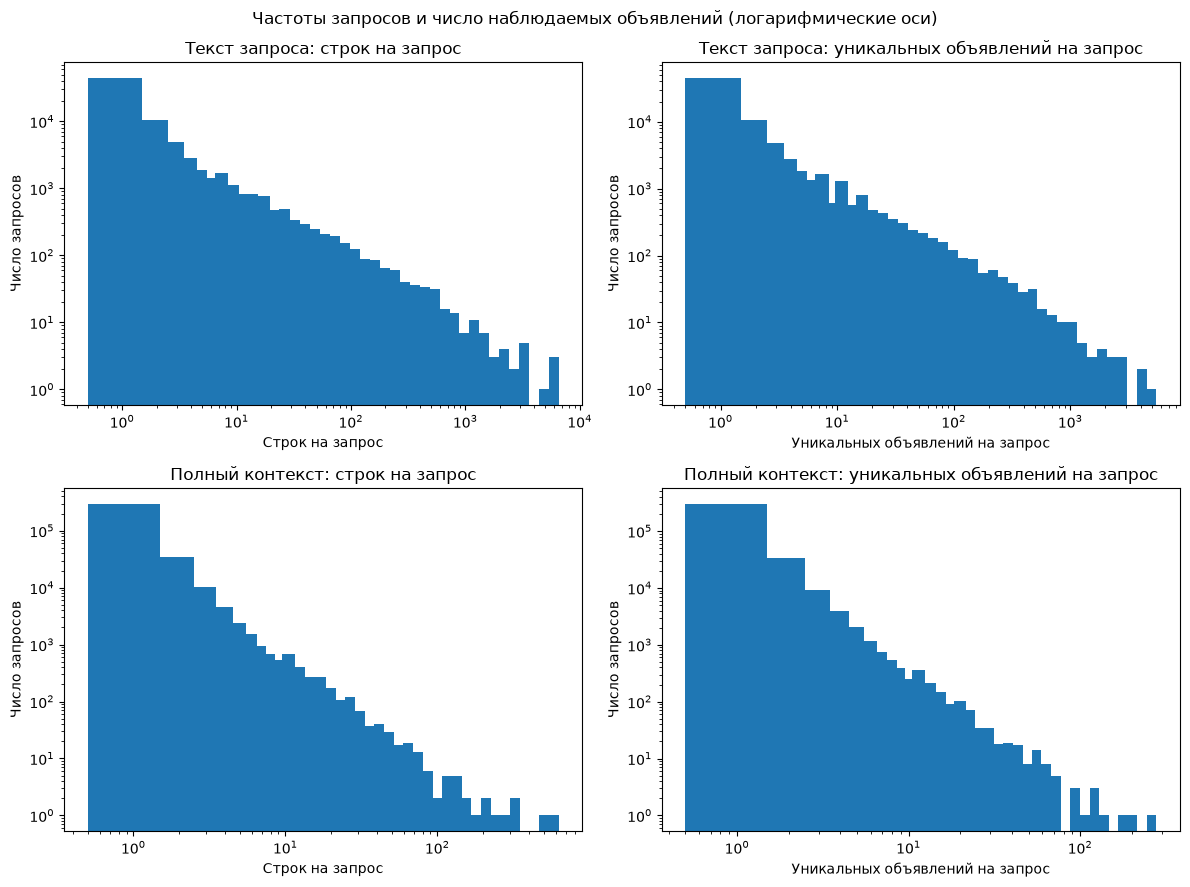

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for row, (name, counts) in enumerate([("Текст запроса", query_counts), ("Полный контекст", context_counts)]):
    for axis, col, label in zip(ax[row], ["n_rows", "n_items"], ["Строк на запрос", "Уникальных объявлений на запрос"]):
        values = counts[col].to_numpy()
        bins = np.unique(np.rint(np.geomspace(1, values.max() + 1, 45))) - 0.5
        axis.hist(values, bins=bins, log=True)
        axis.set_xscale("log")
        axis.set(title=f"{name}: {label.lower()}", xlabel=label, ylabel="Число запросов")

fig.suptitle("Частоты запросов и число наблюдаемых объявлений (логарифмические оси)")
fig.tight_layout()
plt.show()


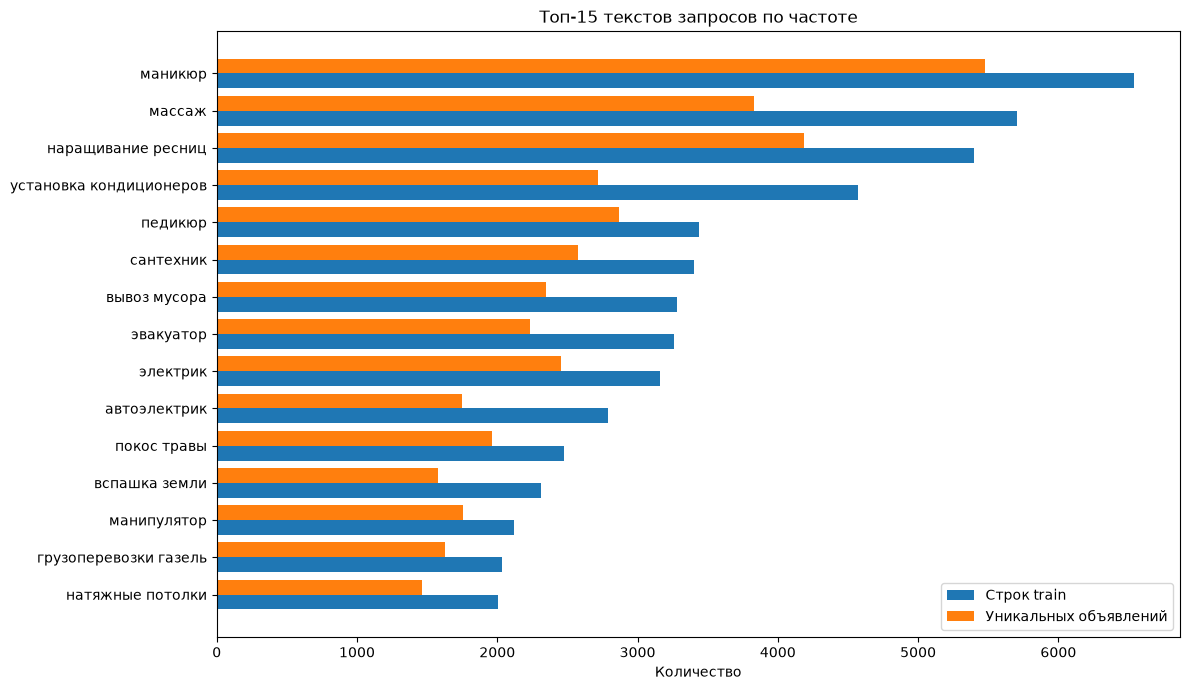

In [ ]:
top_queries = query_counts.head(15).reverse()
positions = np.arange(top_queries.height)
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(positions - 0.2, top_queries["n_rows"].to_list(), height=0.4, label="Строк train")
ax.barh(positions + 0.2, top_queries["n_items"].to_list(), height=0.4, label="Уникальных объявлений")
ax.set_yticks(positions, top_queries["search_query"].to_list())
ax.set(title="Топ-15 текстов запросов по частоте", xlabel="Количество")
ax.legend()
fig.tight_layout()
plt.show()


# Бенчмарки

Запросы и объявления анализируются отдельно: разметки пар здесь нет. Распределения считаются по строкам каждого файла; в train одно объявление может встречаться несколько раз. Гистограммы ID показывают интервалы нумерации, категориальные графики — частоты отдельных ID.


In [ ]:
benchmark_queries_df = pl.scan_parquet(DATA_PATH / BENCH_QUERIES)
benchmark_items_df = pl.scan_parquet(DATA_PATH / BENCH_ITEMS)
benchmarks = {"queries": benchmark_queries_df, "items": benchmark_items_df}

for name, df in benchmarks.items():
    print(50 * "-")
    print(name, "строк:", df.select(pl.len()).collect().item())
    for col, dtype in df.collect_schema().items():
        print(f"Колонка {col} с типом {dtype}")
    print("Пропуски по полям")
    print(df.select(pl.all().null_count()).collect().transpose(include_header=True, column_names=["null_count"]))


--------------------------------------------------
queries строк: 2452
Колонка query_id с типом String
Колонка search_query с типом String
Колонка search_location_id с типом Int64
Колонка search_is_delivery_search с типом Int32
Колонка search_infm_params_text с типом String
Колонка search_category с типом Int64
Пропуски по полям
shape: (6, 2)
┌───────────────────────────┬────────────┐
│ column                    ┆ null_count │
│ ---                       ┆ ---        │
│ str                       ┆ u32        │
╞═══════════════════════════╪════════════╡
│ query_id                  ┆ 0          │
│ search_query              ┆ 0          │
│ search_location_id        ┆ 0          │
│ search_is_delivery_search ┆ 0          │
│ search_infm_params_text   ┆ 0          │
│ search_category           ┆ 0          │
└───────────────────────────┴────────────┘
--------------------------------------------------
items строк: 189212
Колонка item_title_raw с типом String
Колонка item_rating_reviews_co

## Уникальные запросы бенчмарка

Без разметки пар число релевантных объявлений здесь неизвестно.


In [ ]:
benchmark_query_counts = benchmark_queries_df.group_by("search_query").len(name="n_rows").sort("n_rows", descending=True).collect()
print("Бенчмарк: строк запросов", benchmark_query_counts["n_rows"].sum())
print("Бенчмарк: уникальных текстов", benchmark_query_counts.height)
print("Бенчмарк: уникальных контекстов", benchmark_queries_df.select(query_context).unique().select(pl.len()).collect().item())
print("Наиболее частые тексты запросов бенчмарка")
print(benchmark_query_counts.head(15))


Бенчмарк: строк запросов 2452
Бенчмарк: уникальных текстов 2452
Бенчмарк: уникальных контекстов 2452
Наиболее частые тексты запросов бенчмарка
shape: (15, 2)
┌─────────────────────────────────┬────────┐
│ search_query                    ┆ n_rows │
│ ---                             ┆ ---    │
│ str                             ┆ u32    │
╞═════════════════════════════════╪════════╡
│ штукатурные работы              ┆ 1      │
│ монтаж навесов                  ┆ 1      │
│ инструктор по вождению механик… ┆ 1      │
│ варовайка                       ┆ 1      │
│ гидромассаж                     ┆ 1      │
│ сайт пригоашение на день рожде… ┆ 1      │
│ услуга по шлифовка пола деревя… ┆ 1      │
│ 3d визуализация                 ┆ 1      │
│ заправка холодильников          ┆ 1      │
│ ремонт стиральных машин 24 час… ┆ 1      │
│ стрижка каскад на длинные       ┆ 1      │
│ услуги чпу по дереву            ┆ 1      │
│ грузоперевозки переезды газель  ┆ 1      │
│ расчистка участка от деревьев 

## Целочисленные признаки


--------------------------------------------------
queries
search_location_id: уникальных 273, пропусков 0
search_is_delivery_search: уникальных 1, пропусков 0
search_category: уникальных 2, пропусков 0
--------------------------------------------------
items
item_location_id: уникальных 2877, пропусков 0
item_microcat_id: уникальных 752, пропусков 0
item_category_id: уникальных 47, пропусков 0
item_rating_reviews_count: уникальных 1170, пропусков 11615


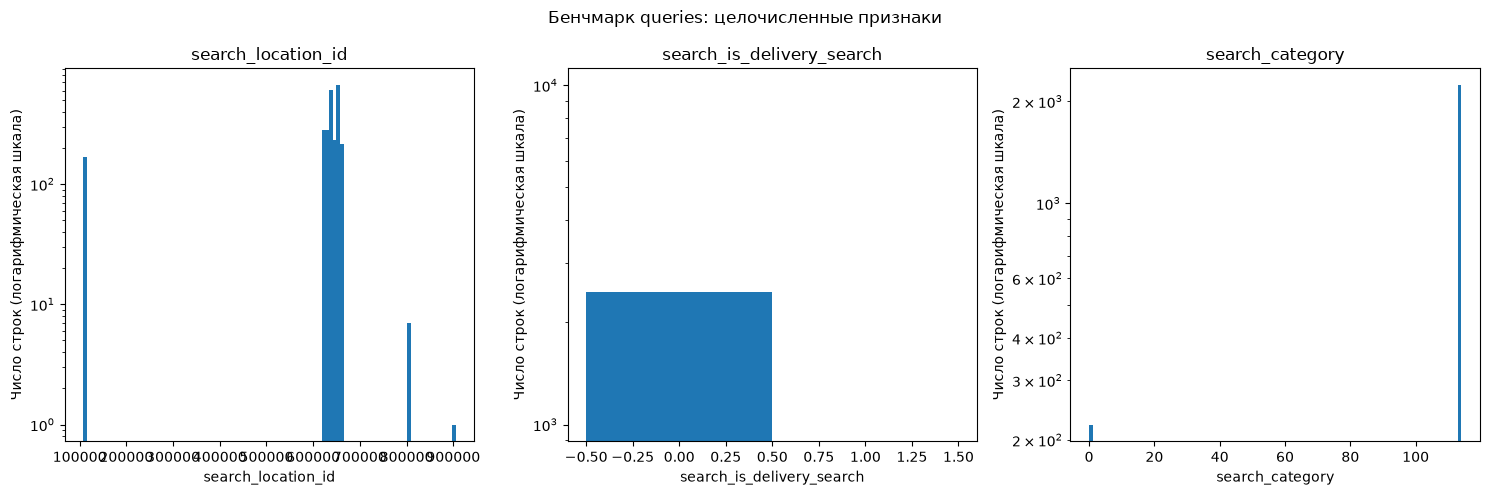

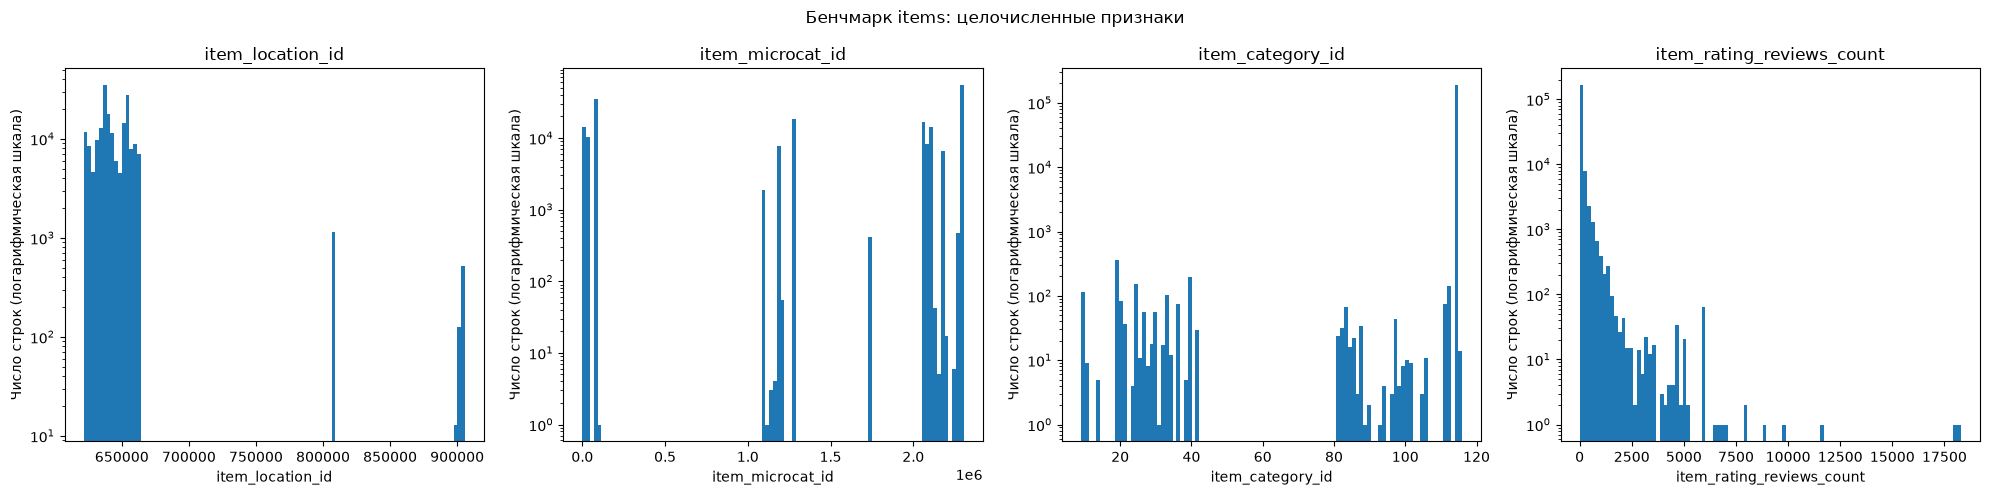

In [ ]:
benchmark_int_cols = {
    "queries": benchmark_queries_df.select("search_location_id", "search_is_delivery_search", "search_category").collect(),
    "items": benchmark_items_df.select(
        "item_location_id", "item_microcat_id", "item_category_id",
        pl.col("item_rating_reviews_count").cast(pl.Int64),
    ).collect(),
}

for name, df in benchmark_int_cols.items():
    print(50 * "-")
    print(name)
    fig, ax = plt.subplots(1, df.width, figsize=(5 * df.width, 5))
    for axis, col in zip(ax, df.columns):
        print(f"{col}: уникальных {df[col].drop_nulls().n_unique()}, пропусков {df[col].null_count()}")
        values = df[col].drop_nulls().to_numpy()
        bins = [-0.5, 0.5, 1.5] if col == "search_is_delivery_search" else 100
        axis.hist(values, bins=bins, log=True)
        axis.set(title=col, xlabel=col, ylabel="Число строк (логарифмическая шкала)")
    fig.suptitle(f"Бенчмарк {name}: целочисленные признаки")
    fig.tight_layout()
    plt.show()


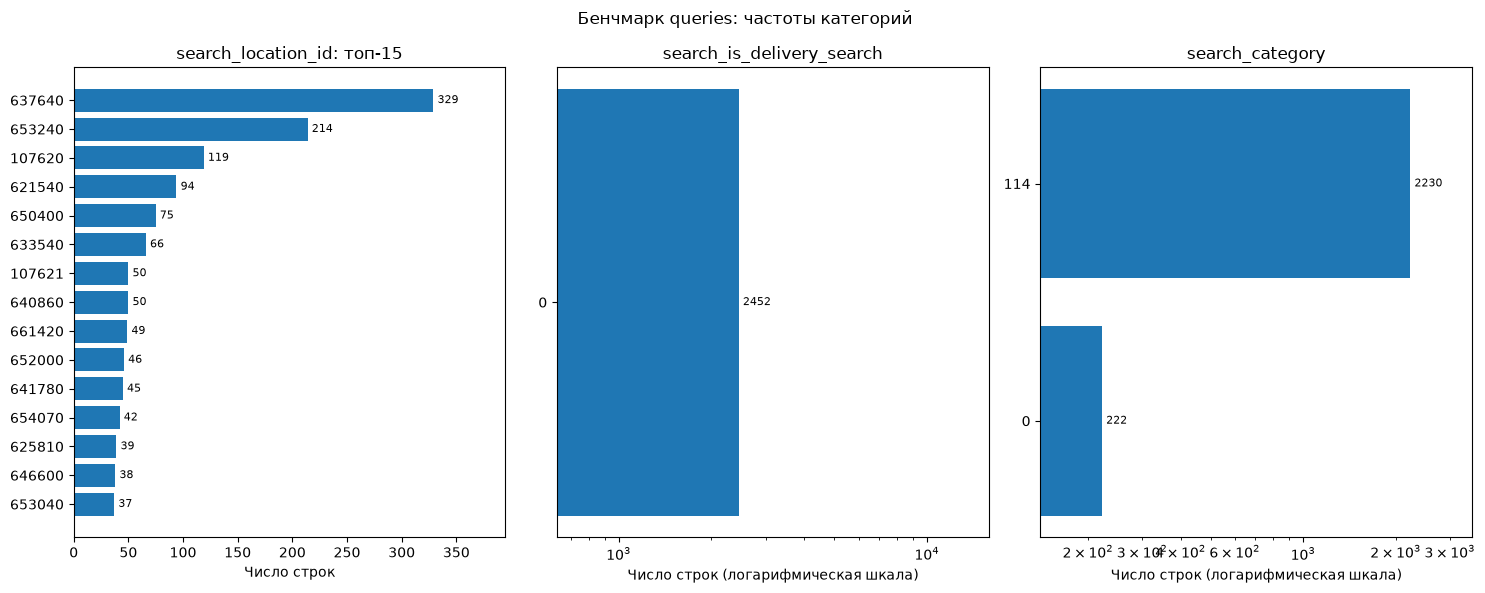

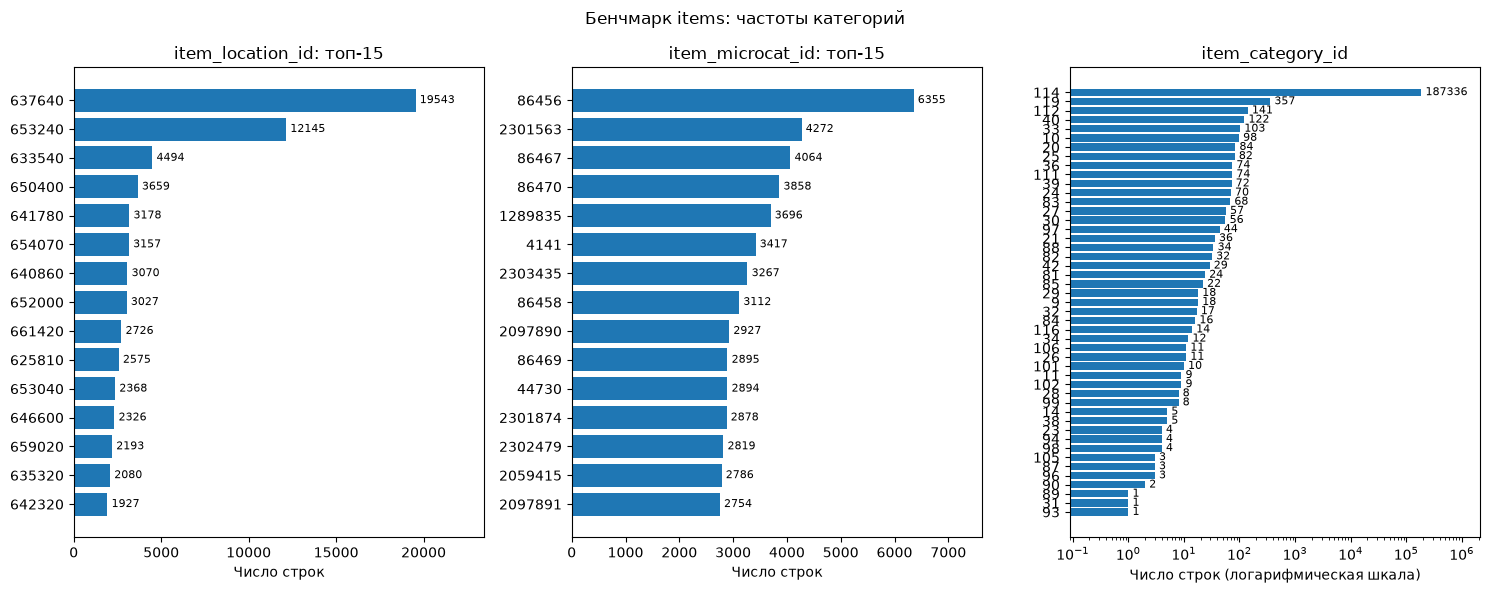

In [ ]:
for name, df in benchmark_int_cols.items():
    cols = [col for col in df.columns if col != "item_rating_reviews_count"]
    fig, ax = plt.subplots(1, len(cols), figsize=(5 * len(cols), 6))
    for axis, col in zip(ax, cols):
        top = 15 if col.endswith("location_id") or col == "item_microcat_id" else None
        title = col + (": топ-15" if top else "")
        category_bar(df[col], axis, title, top=top, log=top is None)
        if top is None:
            axis.set_xlabel("Число строк (логарифмическая шкала)")
    fig.suptitle(f"Бенчмарк {name}: частоты категорий")
    fig.tight_layout()
    plt.show()


## Булевы категориальные признаки объявлений


item_is_phone_hidden: уникальных значений 2, пропусков 0
shape: (2, 3)
┌──────────────────────┬────────┬───────────┐
│ item_is_phone_hidden ┆ count  ┆ percent   │
│ ---                  ┆ ---    ┆ ---       │
│ bool                 ┆ u32    ┆ f64       │
╞══════════════════════╪════════╪═══════════╡
│ false                ┆ 159705 ┆ 84.405323 │
│ true                 ┆ 29507  ┆ 15.594677 │
└──────────────────────┴────────┴───────────┘
item_is_message_forbidden: уникальных значений 2, пропусков 0
shape: (2, 3)
┌───────────────────────────┬────────┬───────────┐
│ item_is_message_forbidden ┆ count  ┆ percent   │
│ ---                       ┆ ---    ┆ ---       │
│ bool                      ┆ u32    ┆ f64       │
╞═══════════════════════════╪════════╪═══════════╡
│ false                     ┆ 184179 ┆ 97.340021 │
│ true                      ┆ 5033   ┆ 2.659979  │
└───────────────────────────┴────────┴───────────┘
Совместные значения флагов
shape: (3, 3)
┌──────────────────────┬────────────

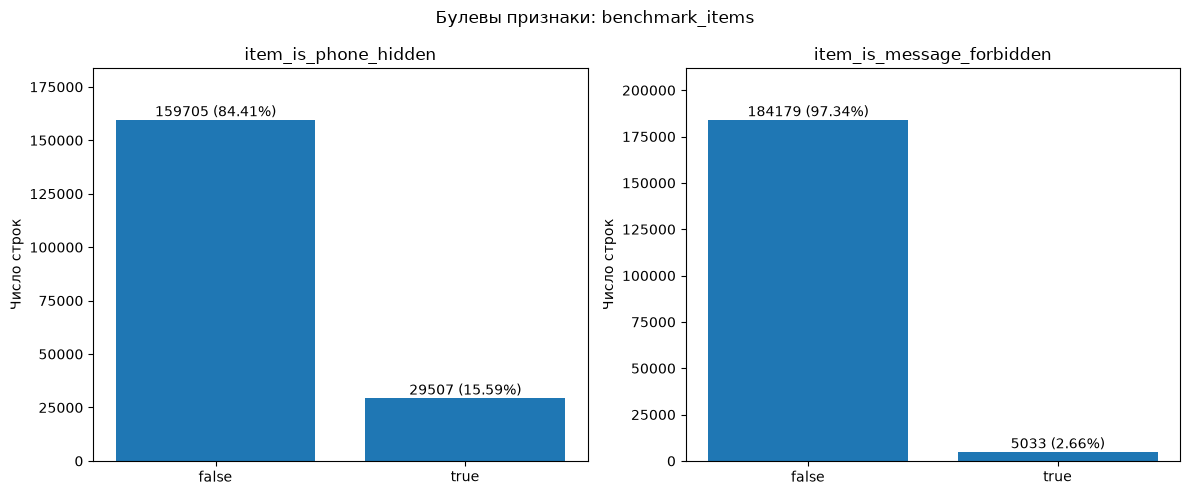

In [ ]:
benchmark_bool_cols = benchmark_items_df.select("item_is_phone_hidden", "item_is_message_forbidden").collect()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axis, col in zip(ax, benchmark_bool_cols.columns):
    print(f"{col}: уникальных значений {benchmark_bool_cols[col].drop_nulls().n_unique()}, пропусков {benchmark_bool_cols[col].null_count()}")
    counts = benchmark_bool_cols[col].value_counts().sort(col).with_columns(
        (100 * pl.col("count") / benchmark_bool_cols.height).alias("percent")
    )
    print(counts)
    bars = axis.bar(counts[col].cast(pl.String).fill_null("null").to_list(), counts["count"].to_list())
    axis.bar_label(bars, labels=[f"{n} ({p:.2f}%)" for n, p in zip(counts["count"], counts["percent"])])
    axis.set(title=col, ylabel="Число строк")
    axis.margins(y=0.15)

print("Совместные значения флагов")
print(benchmark_bool_cols.group_by(benchmark_bool_cols.columns).len().sort("len", descending=True))
fig.suptitle("Булевы признаки: benchmark_items")
fig.tight_layout()
plt.show()


## Непрерывные признаки объявлений


In [ ]:
benchmark_float_cols = benchmark_items_df.select(float_cols.collect_schema().names())
print(benchmark_float_cols.describe())


shape: (9, 5)
┌────────────┬─────────────┬────────────────┬───────────────┬────────────┐
│ statistic  ┆ item_rating ┆ item_longitude ┆ item_latitude ┆ item_price │
│ ---        ┆ ---         ┆ ---            ┆ ---           ┆ ---        │
│ str        ┆ f64         ┆ f64            ┆ f64           ┆ f64        │
╞════════════╪═════════════╪════════════════╪═══════════════╪════════════╡
│ count      ┆ 171581.0    ┆ 189211.0       ┆ 189211.0      ┆ 189212.0   │
│ null_count ┆ 17631.0     ┆ 1.0            ┆ 1.0           ┆ 0.0        │
│ mean       ┆ 4.788894    ┆ 48.216461      ┆ 54.048603     ┆ 1.9860e7   │
│ std        ┆ 0.735973    ┆ 20.312195      ┆ 4.84528       ┆ 3.7306e9   │
│ min        ┆ 0.0         ┆ -65.417659     ┆ -62.613441    ┆ -1.0       │
│ 25%        ┆ 4.876404    ┆ 37.547836      ┆ 52.287052     ┆ 380.0      │
│ 50%        ┆ 5.0         ┆ 39.743112      ┆ 55.550521     ┆ 1000.0     │
│ 75%        ┆ 5.0         ┆ 52.360939      ┆ 56.298492     ┆ 2500.0     │
│ max      

Цена: отрицательных значений 15248, нулей 1340


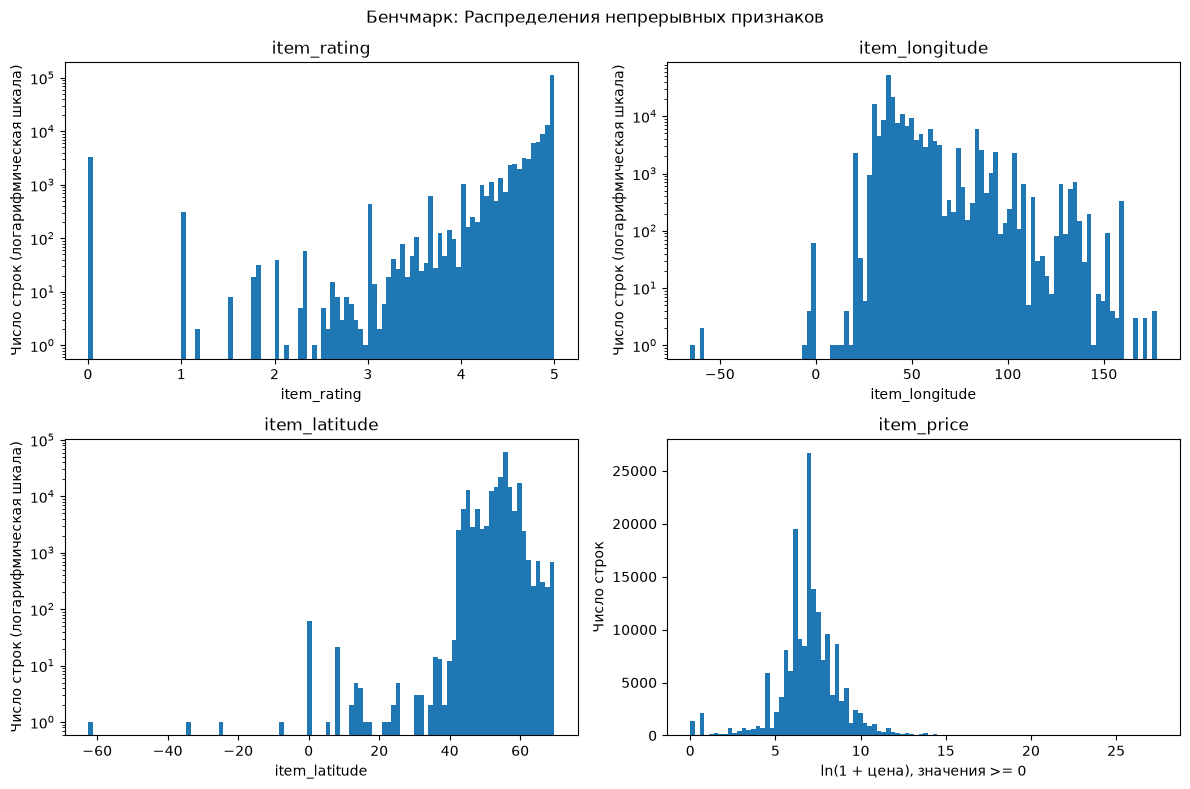

In [ ]:
benchmark_numeric_data = benchmark_float_cols.select(pl.all().cast(pl.Float64)).collect()

fig, ax = plt.subplots((benchmark_numeric_data.width + 1) // 2, 2, figsize=(12, 8), squeeze=False)
for axis, col in zip(ax.flat, benchmark_numeric_data.columns):
    values = benchmark_numeric_data[col].drop_nulls().to_numpy()
    values = values[np.isfinite(values)]
    if col == "item_price":
        print(f"Цена: отрицательных значений {(values < 0).sum()}, нулей {(values == 0).sum()}")
        axis.hist(np.log1p(values[values >= 0]), bins=100)
        axis.set(title=col, xlabel="ln(1 + цена), значения >= 0", ylabel="Число строк")
    else:
        axis.hist(values, bins=100, log=True)
        axis.set(title=col, xlabel=col, ylabel="Число строк (логарифмическая шкала)")

for axis in list(ax.flat)[benchmark_numeric_data.width:]:
    fig.delaxes(axis)
fig.suptitle("Бенчмарк: Распределения непрерывных признаков")
fig.tight_layout()
plt.show()


### KDE

До 20 000 случайных наблюдений, seed=42, сглаживание Скотта; гистограммы нормированы до плотности. Цена после log1p. Хвосты KDE за границами допустимых значений — эффект сглаживания.


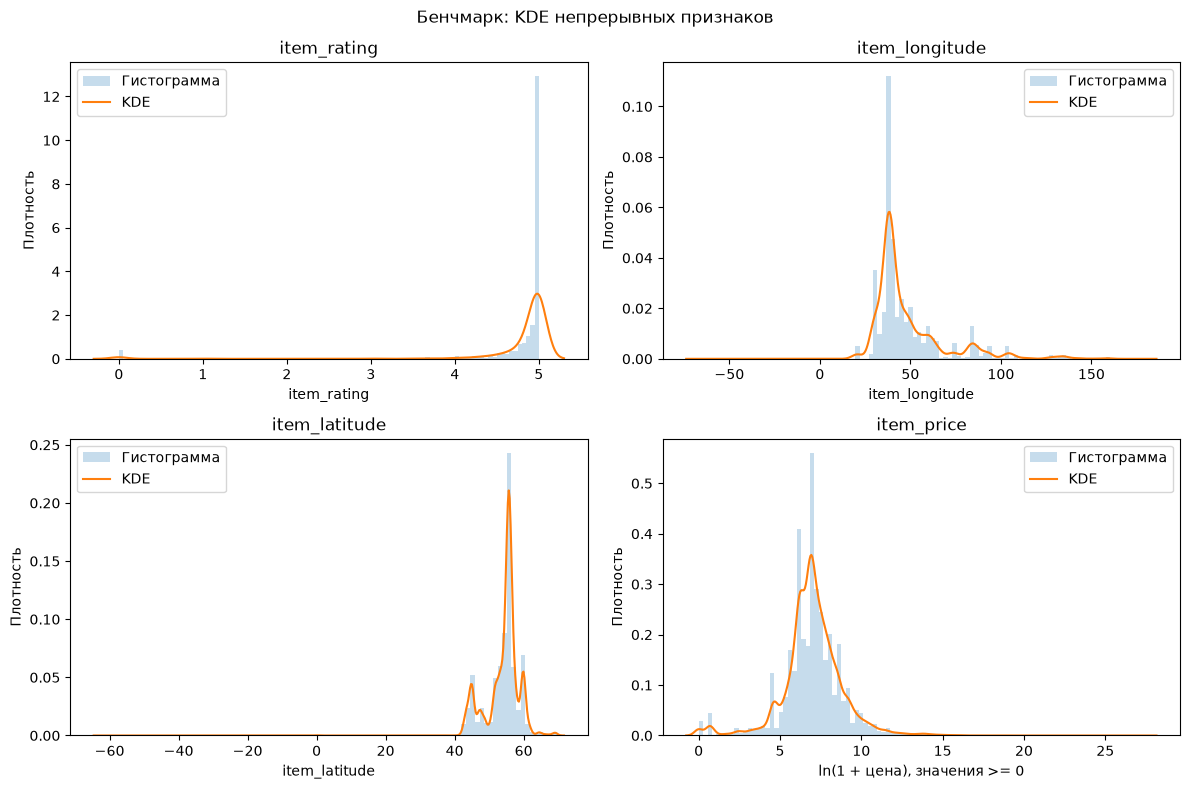

In [ ]:
from matplotlib.mlab import GaussianKDE

benchmark_numeric_data = benchmark_float_cols.select(pl.all().cast(pl.Float64)).collect()
rng = np.random.default_rng(42)

fig, ax = plt.subplots((benchmark_numeric_data.width + 1) // 2, 2, figsize=(12, 8), squeeze=False)
for axis, col in zip(ax.flat, benchmark_numeric_data.columns):
    values = benchmark_numeric_data[col].drop_nulls().to_numpy()
    values = values[np.isfinite(values)]
    xlabel = col
    if col == "item_price":
        values = np.log1p(values[values >= 0])
        xlabel = "ln(1 + цена), значения >= 0"

    sample = rng.choice(values, size=min(20_000, len(values)), replace=False)
    kde = GaussianKDE(sample, bw_method="scott")
    bandwidth = np.sqrt(kde.covariance[0, 0])
    grid = np.linspace(values.min() - 3 * bandwidth, values.max() + 3 * bandwidth, 512)

    axis.hist(values, bins=100, density=True, alpha=0.25, label="Гистограмма")
    axis.plot(grid, kde(grid), label="KDE")
    axis.set(title=col, xlabel=xlabel, ylabel="Плотность")
    axis.legend()

for axis in list(ax.flat)[benchmark_numeric_data.width:]:
    fig.delaxes(axis)
fig.suptitle("Бенчмарк: KDE непрерывных признаков")
fig.tight_layout()
plt.show()


### Совместное распределение координат

Полный диапазон и область между p1 и p99 каждой координаты. У панелей отдельные сетки и цветовые шкалы.


Пар с координатами: 189211, в центральной области: 181763 (96.1%)


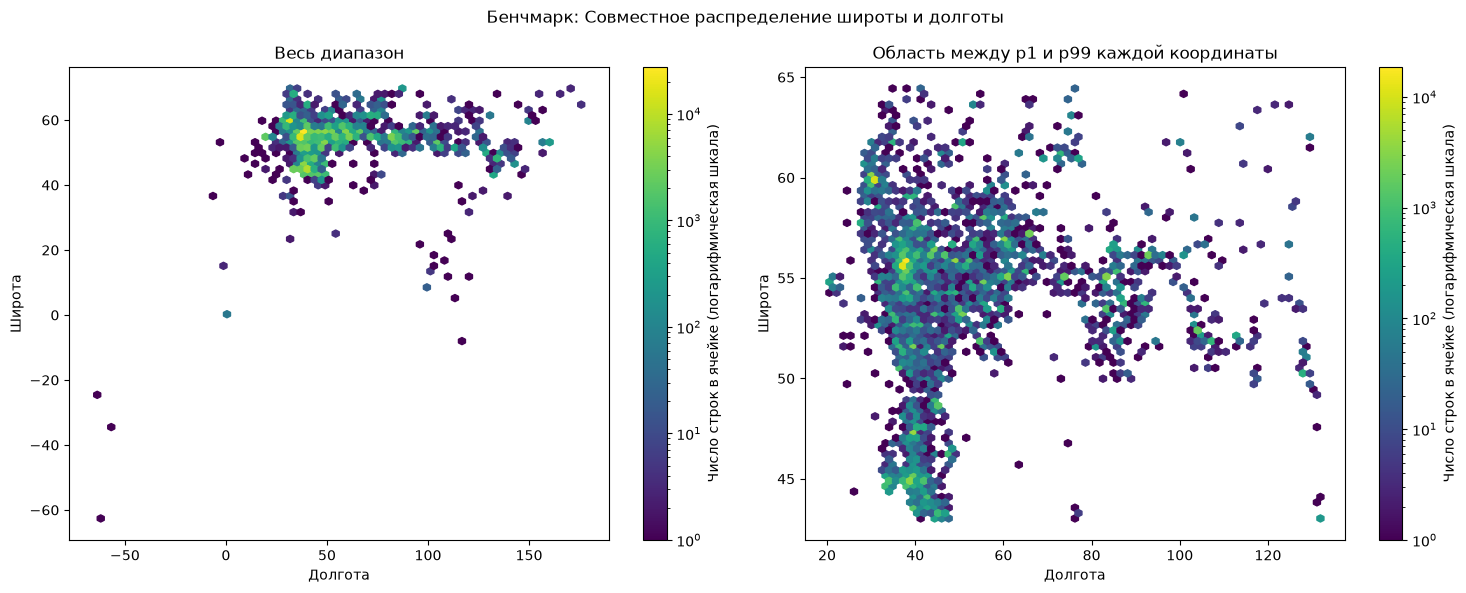

In [ ]:
coordinates = benchmark_numeric_data.select("item_longitude", "item_latitude").drop_nulls().to_numpy()
coordinates = coordinates[np.isfinite(coordinates).all(axis=1)]
longitude, latitude = coordinates.T

lon_min, lon_max = np.quantile(longitude, [0.01, 0.99])
lat_min, lat_max = np.quantile(latitude, [0.01, 0.99])
central = (
    (longitude >= lon_min) & (longitude <= lon_max)
    & (latitude >= lat_min) & (latitude <= lat_max)
)
print(f"Пар с координатами: {len(coordinates)}, в центральной области: {central.sum()} ({central.mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for axis, mask, title in zip(
    ax,
    [np.ones(len(coordinates), dtype=bool), central],
    ["Весь диапазон", "Область между p1 и p99 каждой координаты"],
):
    density = axis.hexbin(
        longitude[mask], latitude[mask],
        gridsize=70, mincnt=1, bins="log", cmap="viridis",
    )
    axis.set(title=title, xlabel="Долгота", ylabel="Широта")
    fig.colorbar(density, ax=axis, label="Число строк в ячейке (логарифмическая шкала)")

fig.suptitle("Бенчмарк: Совместное распределение широты и долготы")
fig.tight_layout()
plt.show()


## Обычный текст

Длина в символах, пустые строки имеют длину 0; null исключены из гистограмм.


queries.search_query: пропусков 0, пустых строк 0
queries.query_id: пропусков 0, пустых строк 0
items.item_title_raw: пропусков 0, пустых строк 0
items.item_description_raw: пропусков 35, пустых строк 0
items.item_id: пропусков 0, пустых строк 0


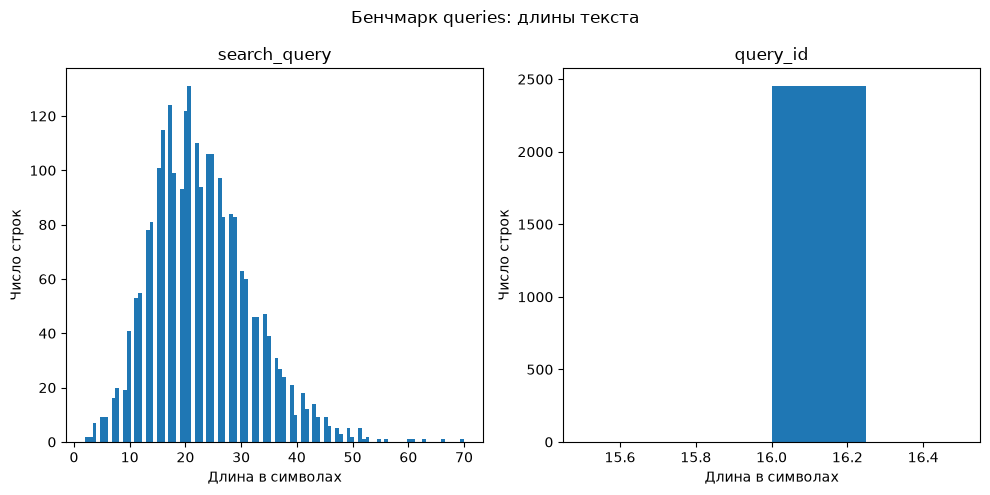

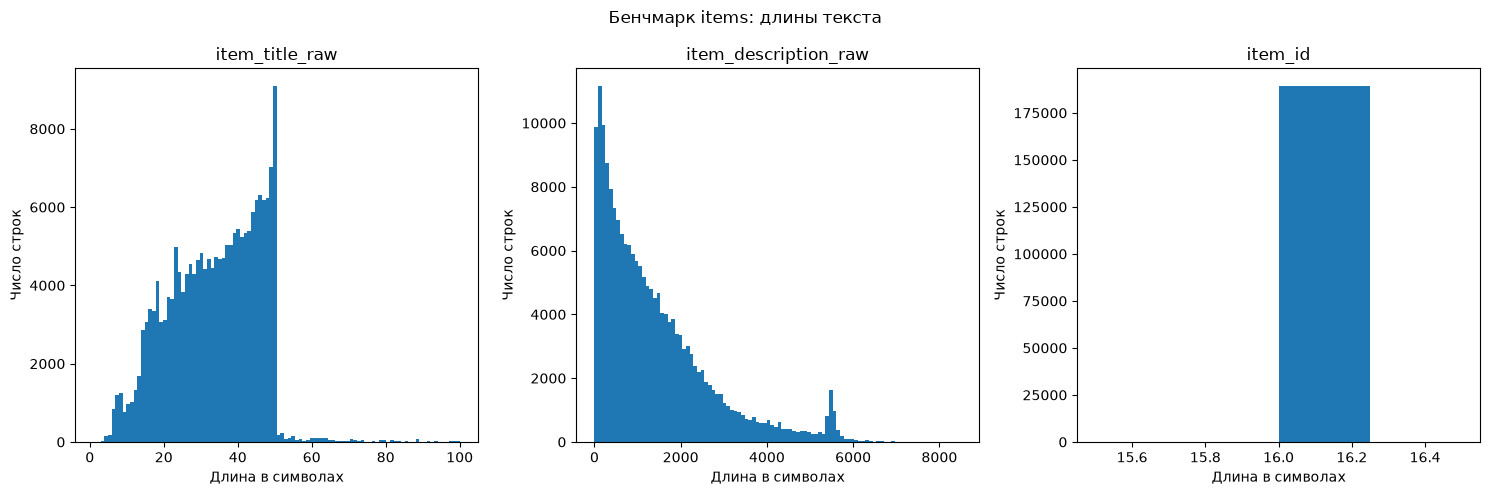

In [ ]:
benchmark_text_fields = {'queries': ['search_query', 'query_id'], 'items': ['item_title_raw', 'item_description_raw', 'item_id']}

for name, cols in benchmark_text_fields.items():
    lengths = benchmarks[name].select(pl.col(col).str.len_chars().alias(col) for col in cols).collect()
    fig, ax = plt.subplots(1, len(cols), figsize=(5 * len(cols), 5), squeeze=False)
    for axis, col in zip(ax.flat, cols):
        values = lengths[col].drop_nulls().to_numpy()
        print(f"{name}.{col}: пропусков {lengths[col].null_count()}, пустых строк {(values == 0).sum()}")
        bins = 4 if col.endswith("_id") else 100
        axis.hist(values, bins=bins)
        axis.set(title=col, xlabel="Длина в символах", ylabel="Число строк")
    fig.suptitle(f"Бенчмарк {name}: длины текста")
    fig.tight_layout()
    plt.show()


## Структурированный текст

Длина в символах, пустые строки имеют длину 0; null исключены из гистограмм.


queries.search_infm_params_text: пропусков 0, пустых строк 1546
items.item_infm_params_text: пропусков 0, пустых строк 0


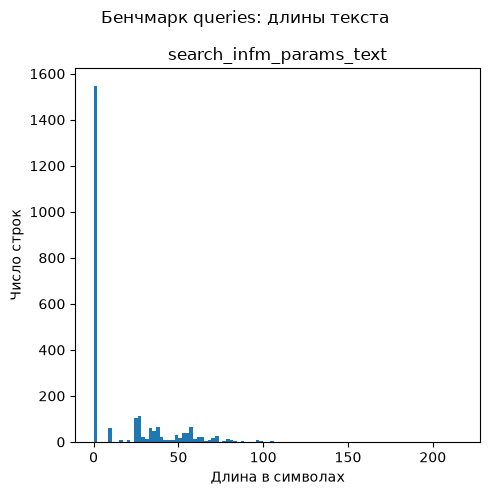

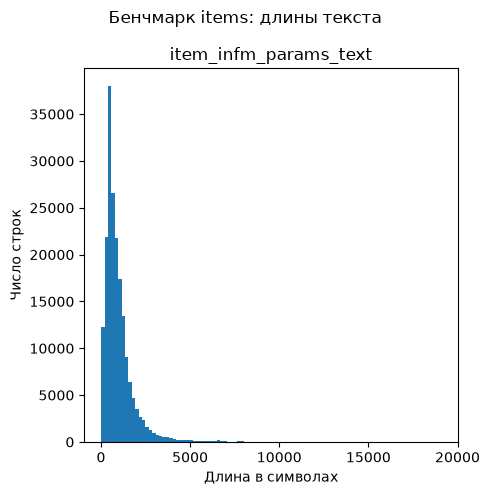

In [ ]:
benchmark_text_fields = {'queries': ['search_infm_params_text'], 'items': ['item_infm_params_text']}

for name, cols in benchmark_text_fields.items():
    lengths = benchmarks[name].select(pl.col(col).str.len_chars().alias(col) for col in cols).collect()
    fig, ax = plt.subplots(1, len(cols), figsize=(5 * len(cols), 5), squeeze=False)
    for axis, col in zip(ax.flat, cols):
        values = lengths[col].drop_nulls().to_numpy()
        print(f"{name}.{col}: пропусков {lengths[col].null_count()}, пустых строк {(values == 0).sum()}")
        bins = 4 if col.endswith("_id") else 100
        axis.hist(values, bins=bins)
        axis.set(title=col, xlabel="Длина в символах", ylabel="Число строк")
    fig.suptitle(f"Бенчмарк {name}: длины текста")
    fig.tight_layout()
    plt.show()
